In [151]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [152]:
df = pd.read_csv("credit_card_fraud_project_dataset_500k.csv")


In [153]:
df.head()


,transaction_id,customer_id,transaction_datetime,transaction_date,transaction_hour,merchant,merchant_category,transaction_amount,payment_method,transaction_status,city,state,customer_latitude,customer_longitude,merchant_latitude,merchant_longitude,city_population,is_fraud
0,164a9d7cc011f54155e746d270d03524,CUST_0E606C366809,2019-08-04 06:51:47,2019-08-04,6,Torp-Labadie,gas_transport,64.07,Swipe,Approved,Alpharetta,GA,34.0770,-84.3033,34.697441,-85.167109,165556,0
1,62466599f86f6c65ad665f7dedea7fe4,CUST_C51B7DBC7448,2020-03-08 11:46:55,2020-03-08,11,"Greenholt, Jacobi and Gleason",gas_transport,70.77,Swipe,Approved,Lawrence,MA,42.6911,-71.1605,42.105635,-71.744017,76383,0
2,4699d5d458cc9e7b0317cad10db9ad25,CUST_6684A1525185,2020-01-12 15:57:29,2020-01-12,15,Harris Group,food_dining,21.84,Chip,Approved,Amorita,OK,36.9412,-98.2458,36.760724,-97.475362,83,0
3,0ec8223375e03bc6aa1b2c8cdb8df5cf,CUST_987E3D10EE11,2020-06-19 19:40:32,2020-06-19,19,Schuppe-Schuppe,food_dining,55.25,Swipe,Approved,Carlotta,CA,40.5070,-123.9743,40.785266,-123.638540,1139,0
4,b3011f4000f41dd273dea2283584f755,CUST_FAB1B59015E0,2019-09-12 16:02:50,2019-09-12,16,"Boehm, Block and Jakubowski",misc_pos,41.10,Online,Approved,Newberg,OR,45.3099,-122.9685,44.755678,-122.072899,28278,0


In [154]:
df.shape


(500000, 18)

In [155]:

df.columns

Index(['transaction_id', 'customer_id', 'transaction_datetime',
       'transaction_date', 'transaction_hour', 'merchant', 'merchant_category',
       'transaction_amount', 'payment_method', 'transaction_status', 'city',
       'state', 'customer_latitude', 'customer_longitude', 'merchant_latitude',
       'merchant_longitude', 'city_population', 'is_fraud'],
      dtype='object')

In [156]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 18 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   transaction_id        500000 non-null  object 
 1   customer_id           500000 non-null  object 
 2   transaction_datetime  500000 non-null  object 
 3   transaction_date      500000 non-null  object 
 4   transaction_hour      500000 non-null  int64  
 5   merchant              500000 non-null  object 
 6   merchant_category     500000 non-null  object 
 7   transaction_amount    500000 non-null  float64
 8   payment_method        500000 non-null  object 
 9   transaction_status    500000 non-null  object 
 10  city                  500000 non-null  object 
 11  state                 500000 non-null  object 
 12  customer_latitude     500000 non-null  float64
 13  customer_longitude    500000 non-null  float64
 14  merchant_latitude     500000 non-null  float64
 15  

In [157]:
df.describe()

,transaction_hour,transaction_amount,customer_latitude,customer_longitude,merchant_latitude,merchant_longitude,city_population,is_fraud
count,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,5.000000e+05,500000.000000
mean,12.798512,70.791888,38.541900,-90.235328,38.541193,-90.235887,8.895801e+04,0.005788
std,6.819564,175.264083,5.076745,13.764867,5.109740,13.776811,3.028615e+05,0.075858
min,0.000000,1.000000,20.027100,-165.672300,19.027804,-166.671242,2.300000e+01,0.000000
25%,7.000000,9.660000,34.668900,-96.798000,34.734409,-96.909155,7.410000e+02,0.000000
50%,14.000000,47.560000,39.354300,-87.476900,39.373487,-87.445994,2.456000e+03,0.000000
75%,19.000000,83.190000,41.940400,-80.158000,41.961716,-80.244573,2.032800e+04,0.000000
max,23.000000,28948.900000,66.693300,-67.950300,67.510267,-66.959178,2.906700e+06,1.000000


In [158]:
df.isnull().sum()

transaction_id          0
customer_id             0
transaction_datetime    0
transaction_date        0
transaction_hour        0
merchant                0
merchant_category       0
transaction_amount      0
payment_method          0
transaction_status      0
city                    0
state                   0
customer_latitude       0
customer_longitude      0
merchant_latitude       0
merchant_longitude      0
city_population         0
is_fraud                0
dtype: int64

In [159]:
df.duplicated().sum()

np.int64(0)

In [160]:
df['is_fraud'].value_counts()

is_fraud
0    497106
1      2894
Name: count, dtype: int64

In [161]:
df = df.drop_duplicates()

In [162]:
df.isnull().sum().sum()

np.int64(0)

In [163]:
df.duplicated().sum()

np.int64(0)

In [164]:
df.shape

(500000, 18)

In [165]:
print("Total Transactions:", df.shape[0])

print("Total Transaction Amount:", df['transaction_amount'].sum())

print("Average Transaction Amount:", df['transaction_amount'].mean())

print("Minimum Transaction Amount:", df['transaction_amount'].min())

print("Maximum Transaction Amount:", df['transaction_amount'].max())

Total Transactions: 500000
Total Transaction Amount: 35395944.089999996
Average Transaction Amount: 70.79188817999999
Minimum Transaction Amount: 1.0
Maximum Transaction Amount: 28948.9


In [166]:
df['transaction_amount'].describe()


count    500000.000000
mean         70.791888
std         175.264083
min           1.000000
25%           9.660000
50%          47.560000
75%          83.190000
max       28948.900000
Name: transaction_amount, dtype: float64

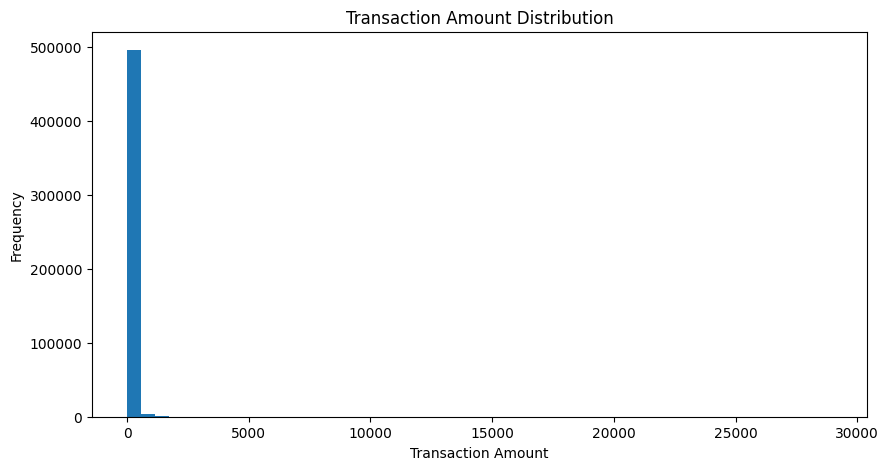

In [167]:
plt.figure(figsize=(10, 5))

plt.hist(df['transaction_amount'], bins=50)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

In [168]:
df.groupby('is_fraud')['transaction_amount'].agg(['count', 'sum', 'mean', 'min', 'max'])

,count,sum,mean,min,max
is_fraud,,,,,
0,497106,33814031.98,68.021774,1.00,28948.90
1,2894,1581912.11,546.617868,1.06,1371.81


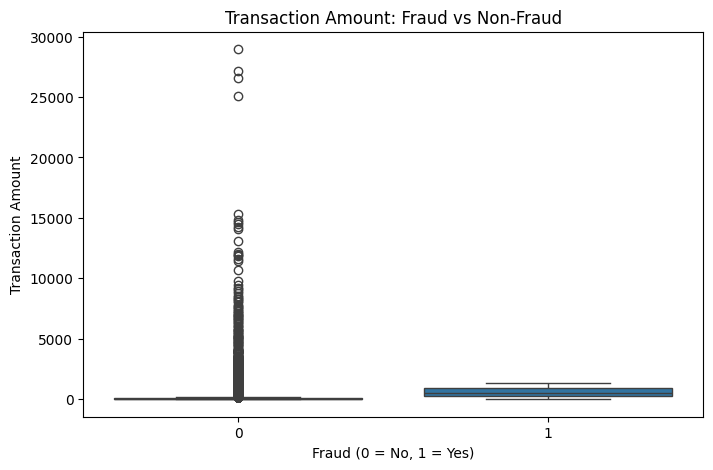

In [169]:
plt.figure(figsize=(8, 5))

sns.boxplot(x='is_fraud', y='transaction_amount', data=df)

plt.title("Transaction Amount: Fraud vs Non-Fraud")
plt.xlabel("Fraud (0 = No, 1 = Yes)")
plt.ylabel("Transaction Amount")

plt.show()

In [170]:
fraud_count = df['is_fraud'].sum()

total_transactions = df.shape[0]

fraud_percentage = (fraud_count / total_transactions) * 100

print("Fraud Transactions:", fraud_count)
print("Fraud Percentage:", fraud_percentage)

Fraud Transactions: 2894
Fraud Percentage: 0.5788


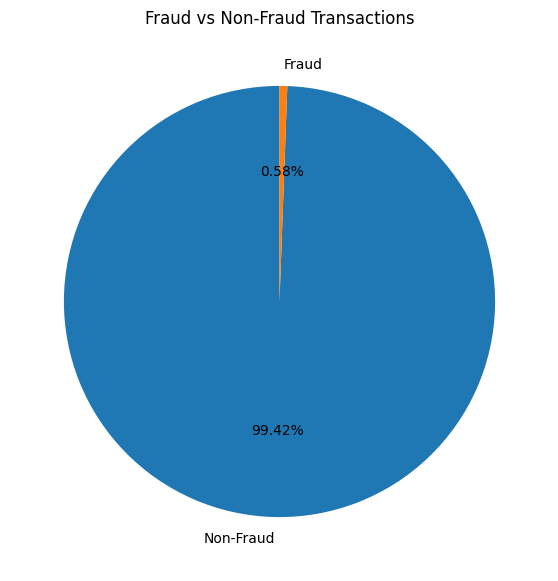

In [171]:
fraud_counts = df['is_fraud'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    fraud_counts,
    labels=['Non-Fraud', 'Fraud'],
    autopct='%1.2f%%',
    startangle=90
)

plt.title("Fraud vs Non-Fraud Transactions")

plt.show()

In [172]:
df.groupby('is_fraud')['transaction_amount'].agg(['count', 'sum', 'mean'])

,count,sum,mean
is_fraud,,,
0,497106,33814031.98,68.021774
1,2894,1581912.11,546.617868


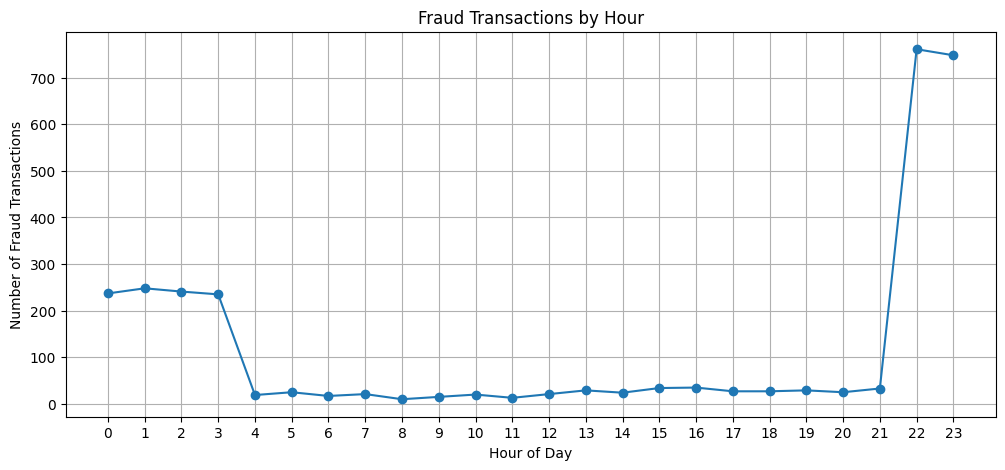

In [173]:
fraud_by_hour = df[df['is_fraud'] == 1].groupby('transaction_hour').size()

plt.figure(figsize=(12, 5))

plt.plot(fraud_by_hour.index, fraud_by_hour.values, marker='o')

plt.title("Fraud Transactions by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Fraud Transactions")

plt.xticks(range(24))

plt.grid()
plt.show()

In [174]:
fraud_by_category = df[df['is_fraud'] == 1].groupby('merchant_category').size().sort_values(ascending=False)

print(fraud_by_category)

merchant_category
shopping_net      693
grocery_pos       641
misc_net          372
shopping_pos      326
gas_transport     247
home               90
misc_pos           89
entertainment      89
kids_pets          85
personal_care      84
food_dining        49
health_fitness     44
travel             43
grocery_net        42
dtype: int64


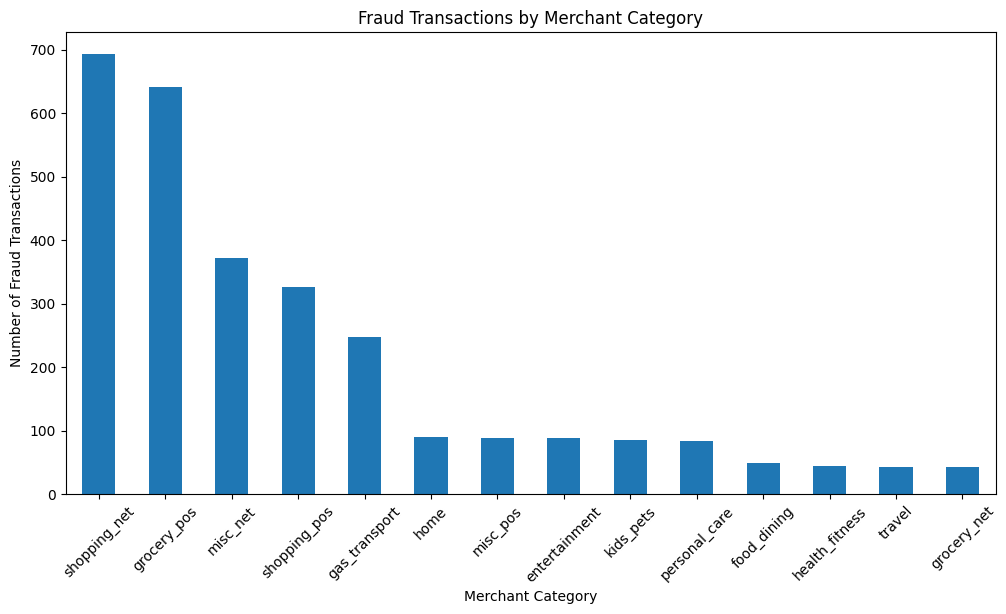

In [175]:
plt.figure(figsize=(12, 6))

fraud_by_category.plot(kind='bar')

plt.title("Fraud Transactions by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Number of Fraud Transactions")
plt.xticks(rotation=45)

plt.show()

In [176]:
fraud_by_state = df[df['is_fraud'] == 1].groupby('state').size().sort_values(ascending=False)

print(fraud_by_state.head(10))

state
NY    208
TX    198
PA    165
OH    130
CA    116
IL    106
FL     98
MO     89
MN     87
MI     87
dtype: int64


In [177]:
fraud_amount = df[df['is_fraud'] == 1]['transaction_amount'].sum()

print("Total Fraud Amount:", fraud_amount)

Total Fraud Amount: 1581912.1099999999


In [178]:
category_fraud_rate = df.groupby('merchant_category')['is_fraud'].mean() * 100

category_fraud_rate = category_fraud_rate.sort_values(ascending=False)

print(category_fraud_rate)

merchant_category
shopping_net      1.846080
misc_net          1.521659
grocery_pos       1.344323
shopping_pos      0.723640
gas_transport     0.486364
misc_pos          0.290110
travel            0.275218
entertainment     0.244143
personal_care     0.240405
grocery_net       0.238001
kids_pets         0.194767
home              0.190351
food_dining       0.139530
health_fitness    0.132882
Name: is_fraud, dtype: float64


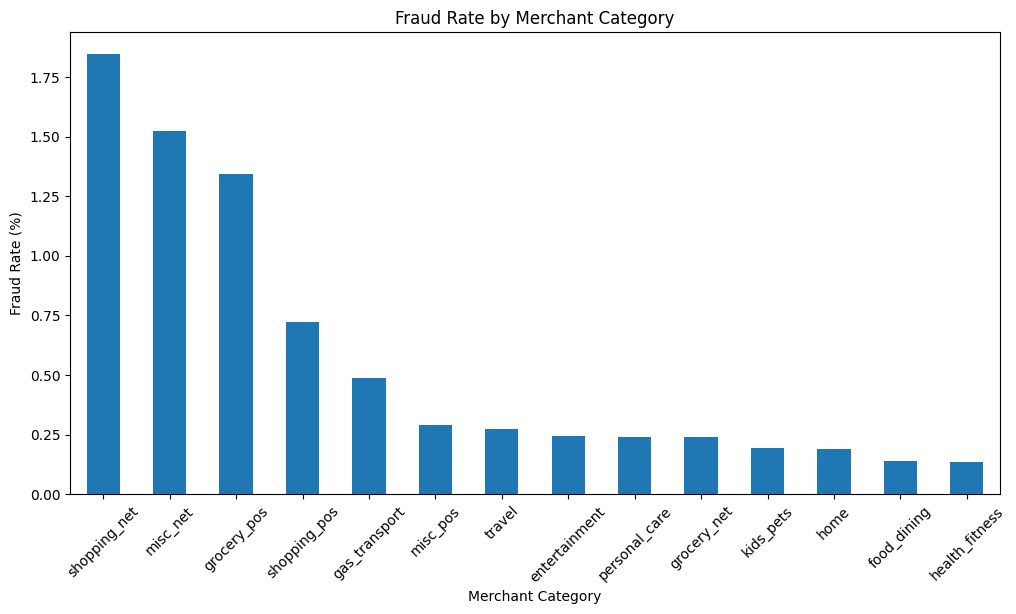

In [179]:
plt.figure(figsize=(12, 6))

category_fraud_rate.plot(kind='bar')

plt.title("Fraud Rate by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45)

plt.show()

In [180]:
transactions_by_hour = df.groupby('transaction_hour').size()

print(transactions_by_hour)

transaction_hour
0     16379
1     16560
2     16407
3     16627
4     16143
5     16316
6     16361
7     16376
8     16454
9     16142
10    16259
11    16212
12    25004
13    25171
14    25025
15    25458
16    25381
17    25142
18    25640
19    25049
20    24847
21    25151
22    25952
23    25944
dtype: int64


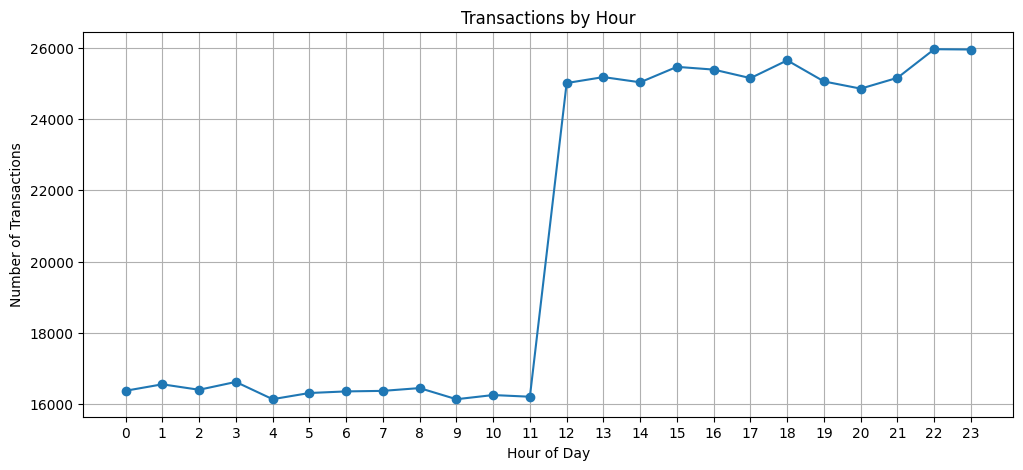

In [181]:
plt.figure(figsize=(12, 5))

plt.plot(transactions_by_hour.index, transactions_by_hour.values, marker='o')

plt.title("Transactions by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")

plt.xticks(range(24))
plt.grid()

plt.show()

In [182]:
avg_amount_by_hour = df.groupby('transaction_hour')['transaction_amount'].mean()

print(avg_amount_by_hour)

transaction_hour
0     80.083069
1     79.548278
2     80.399284
3     79.598176
4     76.240668
5     76.021575
6     75.980590
7     74.589697
8     77.141352
9     74.962795
10    75.965322
11    76.404512
12    61.447985
13    63.227499
14    63.823676
15    63.007723
16    65.025352
17    65.131760
18    63.299316
19    63.538036
20    64.999946
21    63.888091
22    81.650919
23    79.513947
Name: transaction_amount, dtype: float64


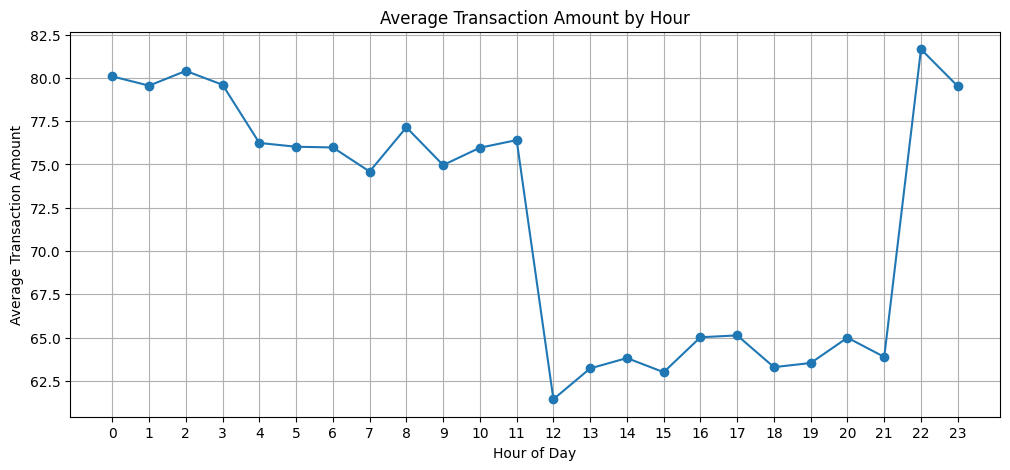

In [183]:
plt.figure(figsize=(12, 5))

plt.plot(avg_amount_by_hour.index, avg_amount_by_hour.values, marker='o')

plt.title("Average Transaction Amount by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Transaction Amount")

plt.xticks(range(24))
plt.grid()

plt.show()

In [184]:
customer_spending = df.groupby('customer_id')['transaction_amount'].sum().sort_values(ascending=False)

print(customer_spending.head(10))

customer_id
CUST_3F128965B93D    121905.68
CUST_A3A62304E057    114755.28
CUST_FA46922D7B8A    113715.86
CUST_8715D9E40DC2    112027.96
CUST_CD81464D3E96    111833.19
CUST_5B9E1E38487F    111076.21
CUST_82BC011F90F9    110738.66
CUST_E2097D89A4B2    110403.78
CUST_B82BF3D7EBC1    110297.57
CUST_B4FA0AABA467    108153.52
Name: transaction_amount, dtype: float64


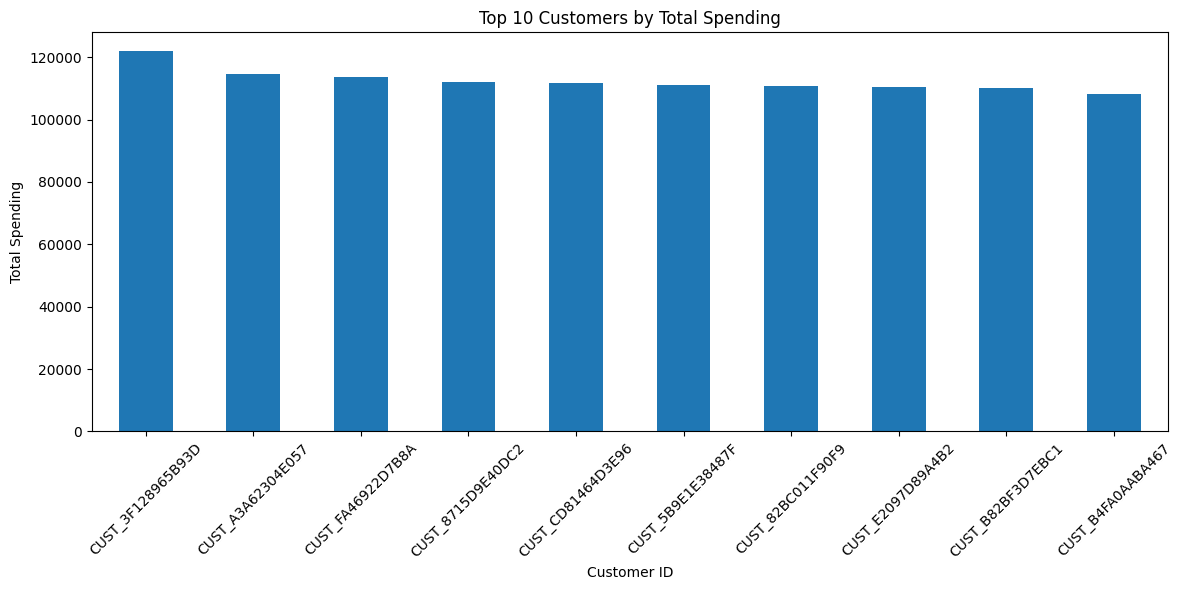

In [185]:
top_10_customers = customer_spending.head(10)

plt.figure(figsize=(12, 6))

top_10_customers.plot(kind='bar')

plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [186]:
average_customer_spending = df.groupby('customer_id')['transaction_amount'].mean()

print("Average Customer Spending:", average_customer_spending.mean())

Average Customer Spending: 113.00028949142796


In [187]:
avg_spending_customer = df.groupby('customer_id')['transaction_amount'].mean().sort_values(ascending=False)

print(avg_spending_customer.head(10))

customer_id
CUST_AE7EE5CA769E    1313.180000
CUST_CF84FA9F6176    1068.723333
CUST_8ED14BE70EB6     996.142500
CUST_1A6B46C00834     978.290000
CUST_2500FE93E640     970.360000
CUST_7D2FDD2C2438     961.450000
CUST_F59A12447917     960.753333
CUST_EAE282F98805     929.987500
CUST_793AEAB05401     923.407500
CUST_C64112662753     906.475000
Name: transaction_amount, dtype: float64


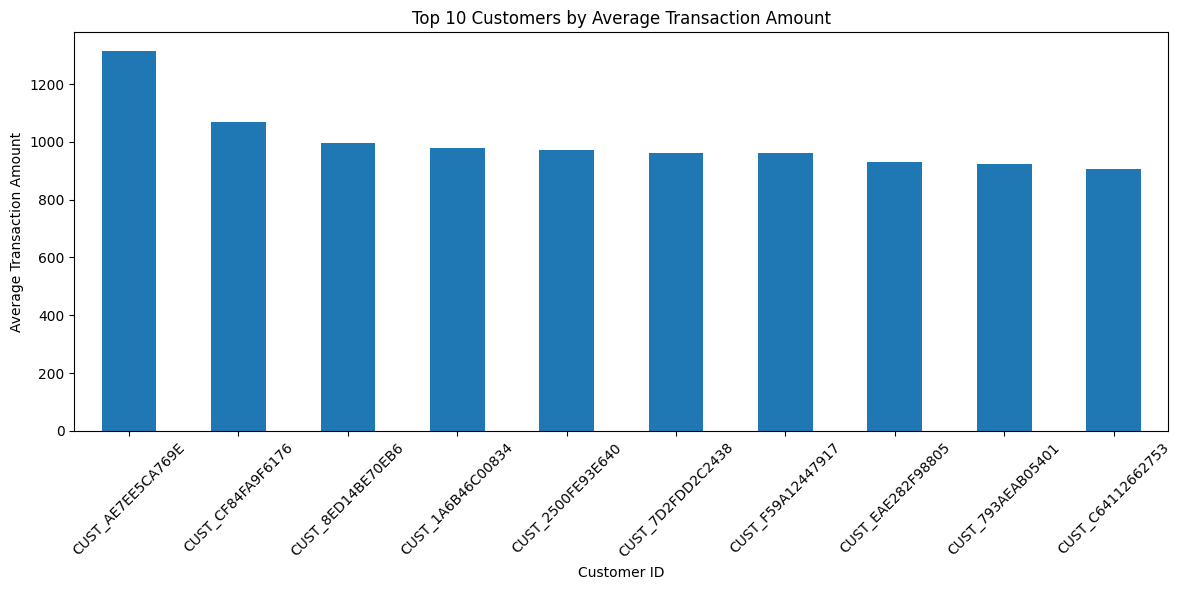

In [188]:
top_10_avg_customers = avg_spending_customer.head(10)

plt.figure(figsize=(12, 6))

top_10_avg_customers.plot(kind='bar')

plt.title("Top 10 Customers by Average Transaction Amount")
plt.xlabel("Customer ID")
plt.ylabel("Average Transaction Amount")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [189]:
fraud_customers = df[df['is_fraud'] == 1].groupby('customer_id').size().sort_values(ascending=False)

print(fraud_customers.head(10))



customer_id
CUST_0340538D8B29    10
CUST_4687CEAD8DED    10
CUST_6ECAE9DE0A50     9
CUST_9A34AEC9DABE     9
CUST_5379911D4E34     9
CUST_5B32948AEC52     9
CUST_C275D8E610DB     9
CUST_BFC5C9F1DC5E     9
CUST_764DBCD4FC8F     9
CUST_14A503C2C0A0     9
dtype: int64


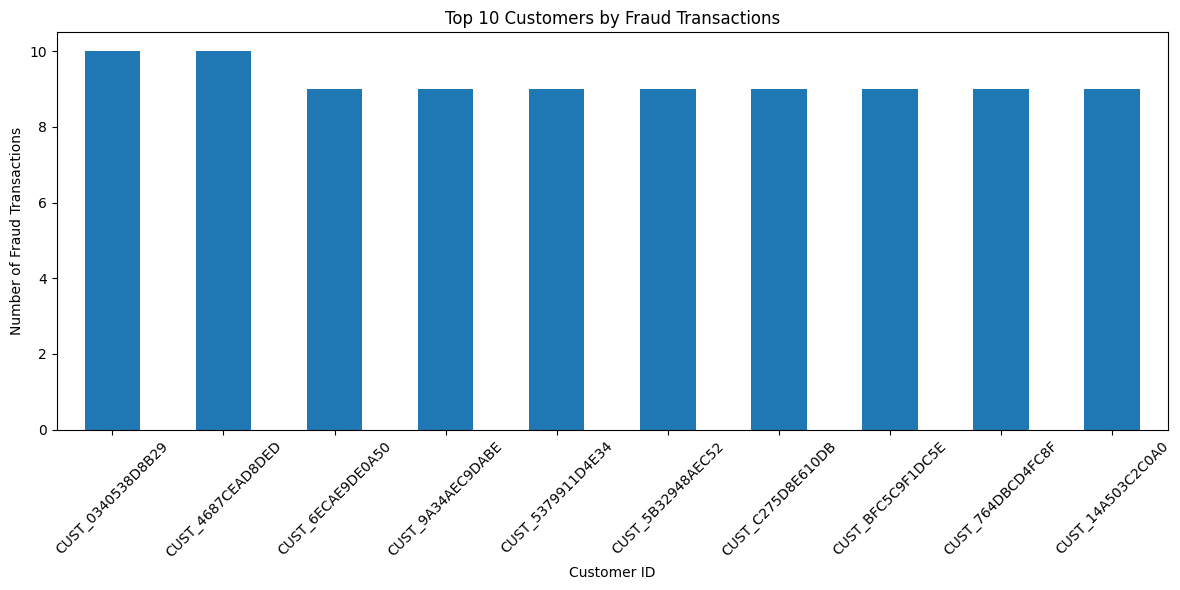

In [190]:
top_10_fraud_customers = fraud_customers.head(10)

plt.figure(figsize=(12, 6))

top_10_fraud_customers.plot(kind='bar')

plt.title("Top 10 Customers by Fraud Transactions")
plt.xlabel("Customer ID")
plt.ylabel("Number of Fraud Transactions")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [191]:
fraud_customer_amount = df[df['is_fraud'] == 1].groupby('customer_id')['transaction_amount'].sum().sort_values(ascending=False)

print(fraud_customer_amount.head(10))

customer_id
CUST_C275D8E610DB    6211.42
CUST_F9D884D74B97    6143.50
CUST_E3C75A872838    6027.59
CUST_D78A9869D2AB    5970.65
CUST_E09C833528C9    5717.55
CUST_4BB515C9D14A    5526.53
CUST_A5154695C553    5489.31
CUST_5379911D4E34    5450.83
CUST_467F5606CAAD    5369.47
CUST_C881EA443AEE    5358.05
Name: transaction_amount, dtype: float64


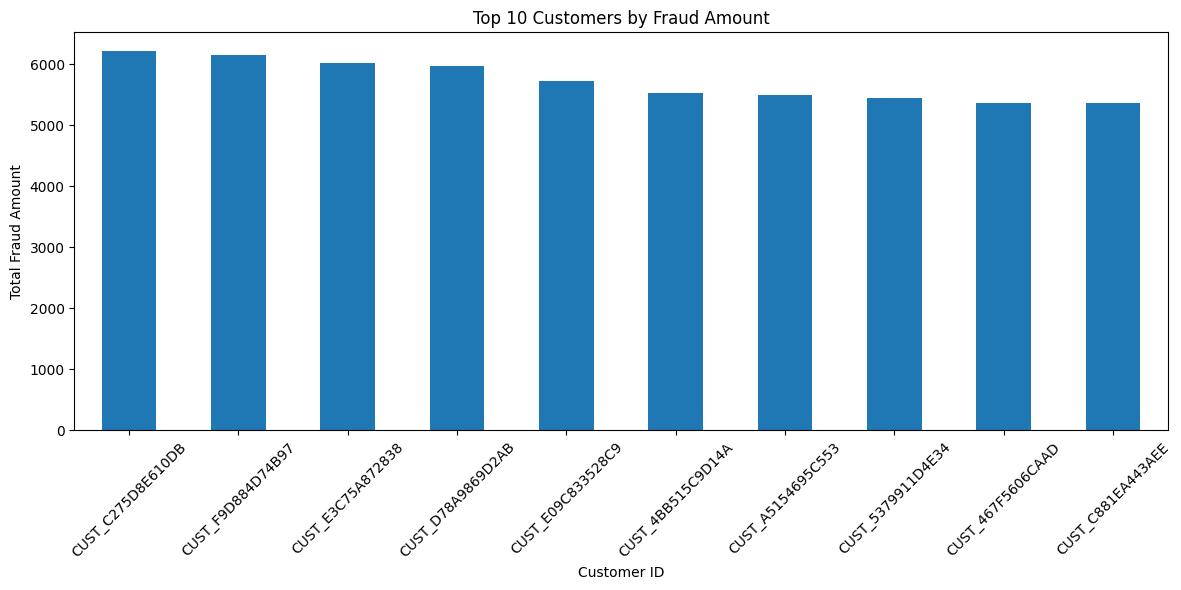

In [192]:
top_10_fraud_amount = fraud_customer_amount.head(10)

plt.figure(figsize=(12, 6))

top_10_fraud_amount.plot(kind='bar')

plt.title("Top 10 Customers by Fraud Amount")
plt.xlabel("Customer ID")
plt.ylabel("Total Fraud Amount")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [193]:
transactions_by_category = df.groupby('merchant_category').size().sort_values(ascending=False)

print(transactions_by_category)

merchant_category
gas_transport     50785
grocery_pos       47682
home              47281
shopping_pos      45050
kids_pets         43642
shopping_net      37539
entertainment     36454
food_dining       35118
personal_care     34941
health_fitness    33112
misc_pos          30678
misc_net          24447
grocery_net       17647
travel            15624
dtype: int64


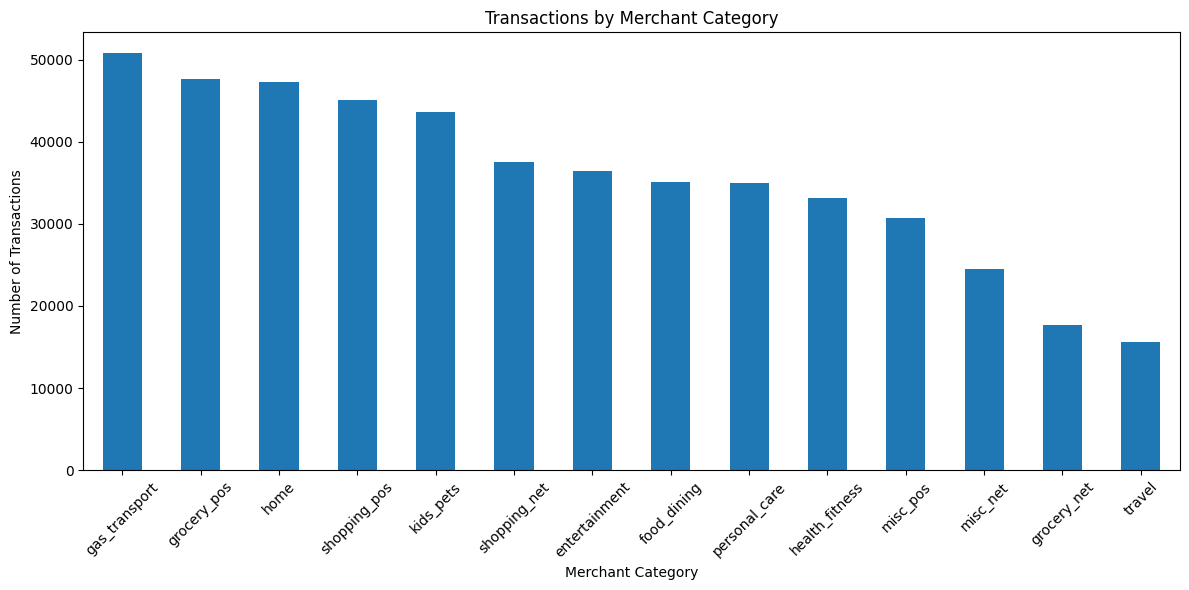

In [194]:
plt.figure(figsize=(12, 6))

transactions_by_category.plot(kind='bar')

plt.title("Transactions by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [195]:
gender_transactions = df.groupby('gender').size()

print(gender_transactions)

plt.figure(figsize=(8,5))

gender_transactions.plot(kind='bar')

plt.title("Transactions by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")

plt.grid(axis='y')
plt.show()

KeyError: 'gender'

In [196]:
print(df.columns)

Index(['transaction_id', 'customer_id', 'transaction_datetime',
       'transaction_date', 'transaction_hour', 'merchant', 'merchant_category',
       'transaction_amount', 'payment_method', 'transaction_status', 'city',
       'state', 'customer_latitude', 'customer_longitude', 'merchant_latitude',
       'merchant_longitude', 'city_population', 'is_fraud'],
      dtype='object')


In [197]:
gender_transactions = df.groupby('Gender').size()

print(gender_transactions)

KeyError: 'Gender'

In [198]:
for col in df.columns:
    print(col)
    

transaction_id
customer_id
transaction_datetime
transaction_date
transaction_hour
merchant
merchant_category
transaction_amount
payment_method
transaction_status
city
state
customer_latitude
customer_longitude
merchant_latitude
merchant_longitude
city_population
is_fraud


In [199]:
payment_transactions = df.groupby('payment_method').size().sort_values(ascending=False)

print(payment_transactions)

payment_method
Chip           170196
Swipe          130322
Online         124962
Contactless     74520
dtype: int64


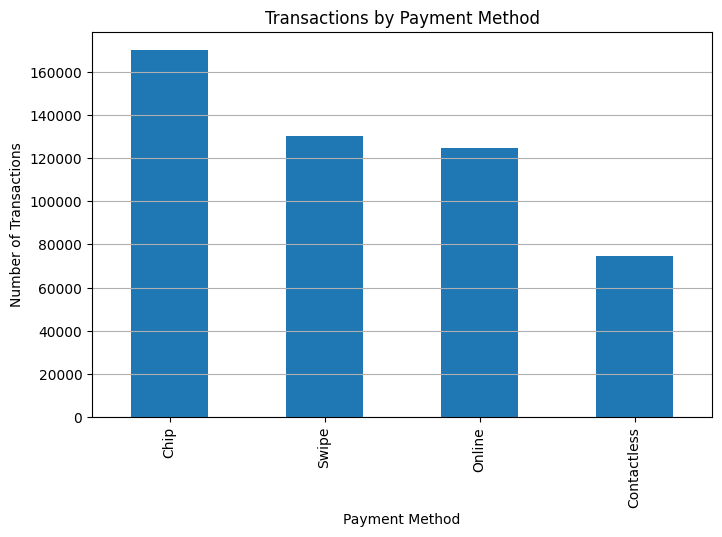

In [200]:
plt.figure(figsize=(8,5))

payment_transactions.plot(kind='bar')

plt.title("Transactions by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")

plt.grid(axis='y')
plt.show()

In [201]:
fraud_by_payment = df[df['is_fraud'] == 1].groupby('payment_method').size().sort_values(ascending=False)

print(fraud_by_payment)

payment_method
Chip           998
Swipe          742
Online         704
Contactless    450
dtype: int64


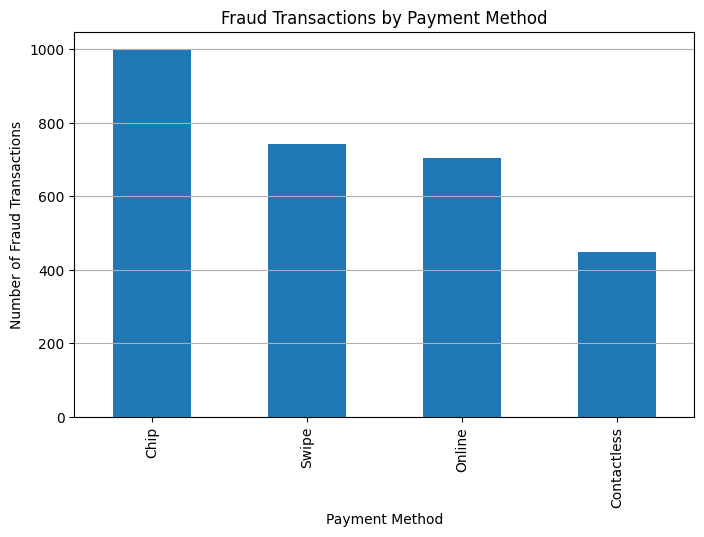

In [202]:
plt.figure(figsize=(8,5))

fraud_by_payment.plot(kind='bar')

plt.title("Fraud Transactions by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Fraud Transactions")

plt.grid(axis='y')
plt.show()

In [203]:
fraud_rate_payment = df.groupby('payment_method')['is_fraud'].mean() * 100

fraud_rate_payment = fraud_rate_payment.sort_values(ascending=False)

print(fraud_rate_payment)

payment_method
Contactless    0.603865
Chip           0.586383
Swipe          0.569359
Online         0.563371
Name: is_fraud, dtype: float64


In [204]:
fraud_by_status = df[df['is_fraud'] == 1].groupby('transaction_status').size()

print(fraud_by_status)


transaction_status
Approved    2780
Declined      66
Pending       11
Reversed      37
dtype: int64


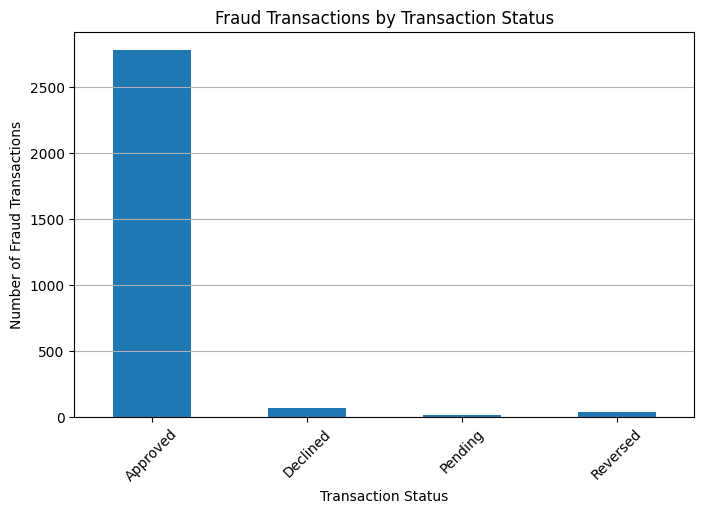

In [205]:
plt.figure(figsize=(8,5))

fraud_by_status.plot(kind='bar')

plt.title("Fraud Transactions by Transaction Status")
plt.xlabel("Transaction Status")
plt.ylabel("Number of Fraud Transactions")
plt.xticks(rotation=45)

plt.grid(axis='y')
plt.show()

In [206]:
fraud_by_state = df[df['is_fraud'] == 1].groupby('state').size().sort_values(ascending=False)

print(fraud_by_state.head(10))

state
NY    208
TX    198
PA    165
OH    130
CA    116
IL    106
FL     98
MO     89
MN     87
MI     87
dtype: int64


In [207]:
fraud_rate_state = df.groupby('state')['is_fraud'].mean() * 100

fraud_rate_state = fraud_rate_state.sort_values(ascending=False)

print(fraud_rate_state.head(10))

state
DE    100.000000
RI      3.755869
AK      2.319902
OR      0.881179
CO      0.788584
NH      0.763602
NE      0.741290
OH      0.723106
ME      0.715842
MN      0.711656
Name: is_fraud, dtype: float64


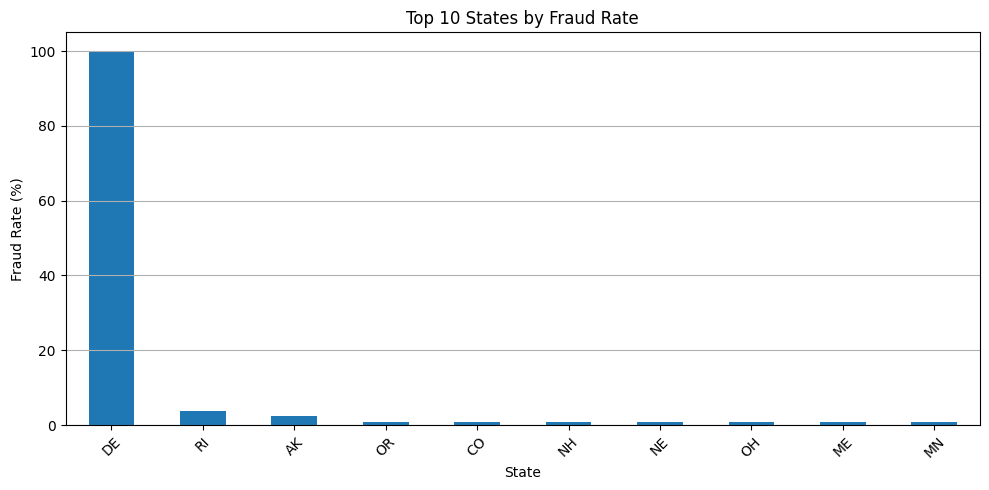

In [208]:
plt.figure(figsize=(10, 5))

fraud_rate_state.head(10).plot(kind='bar')

plt.title('Top 10 States by Fraud Rate')
plt.xlabel('State')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()
plt.show()

In [209]:
fraud_by_city = df[df['is_fraud'] == 1].groupby('city').size().sort_values(ascending=False)

print(fraud_by_city.head(10))

city
Houston        18
Tulsa          14
San Antonio    13
Utica          12
Bay City       12
Warren         11
Naples         11
Detroit        11
Albuquerque    10
Lowell         10
dtype: int64


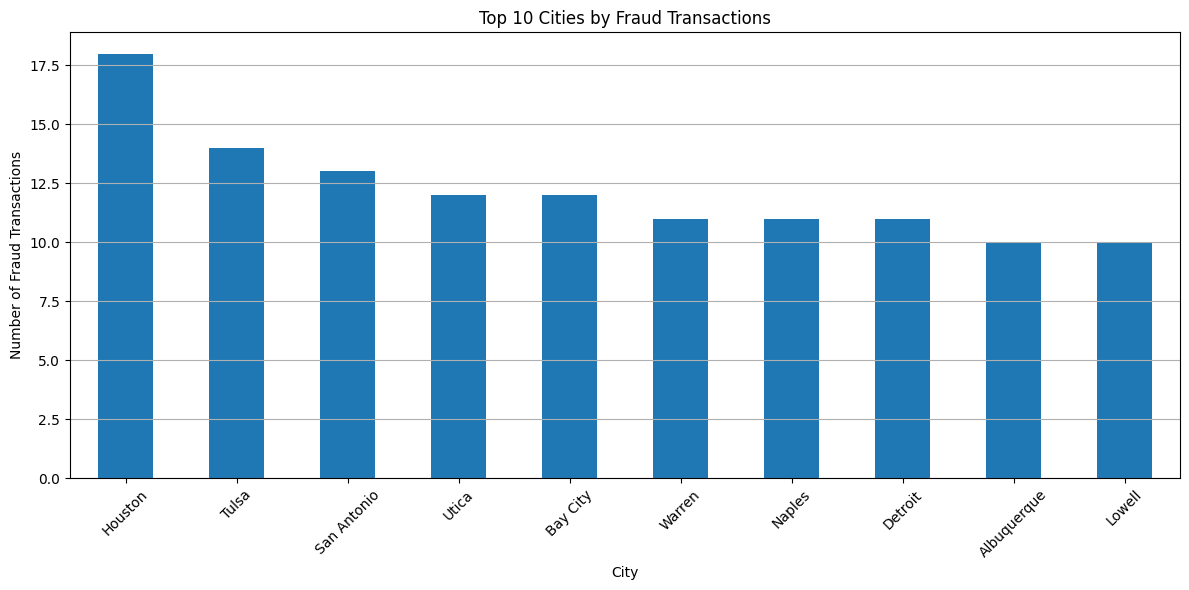

In [210]:
plt.figure(figsize=(12, 6))

fraud_by_city.head(10).plot(kind='bar')

plt.title('Top 10 Cities by Fraud Transactions')
plt.xlabel('City')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()
plt.show()

In [211]:
fraud_rate_city = df.groupby('city')['is_fraud'].mean() * 100

fraud_rate_city = fraud_rate_city.sort_values(ascending=False)

print(fraud_rate_city.head(10))

city
Gaines        100.0
Wappapello    100.0
Vacaville     100.0
Walkertown    100.0
Beacon        100.0
Irvington     100.0
Isanti        100.0
Hubbell       100.0
Freeport      100.0
Waukau        100.0
Name: is_fraud, dtype: float64


In [212]:
city_transactions = df.groupby('city').size().sort_values(ascending=False)

print(city_transactions.loc[fraud_rate_city.head(10).index])

city
Gaines        3
Wappapello    4
Vacaville     3
Walkertown    2
Beacon        4
Irvington     5
Isanti        5
Hubbell       5
Freeport      5
Waukau        3
dtype: int64


In [213]:
fraud_amount_state = df[df['is_fraud'] == 1].groupby('state')['transaction_amount'].sum().sort_values(ascending=False)

print(fraud_amount_state.head(10))

state
NY    118859.83
TX    108792.19
PA     90247.26
OH     66807.31
FL     57713.88
CA     57027.70
IL     55182.09
AL     51317.57
MN     48107.73
MI     47051.71
Name: transaction_amount, dtype: float64


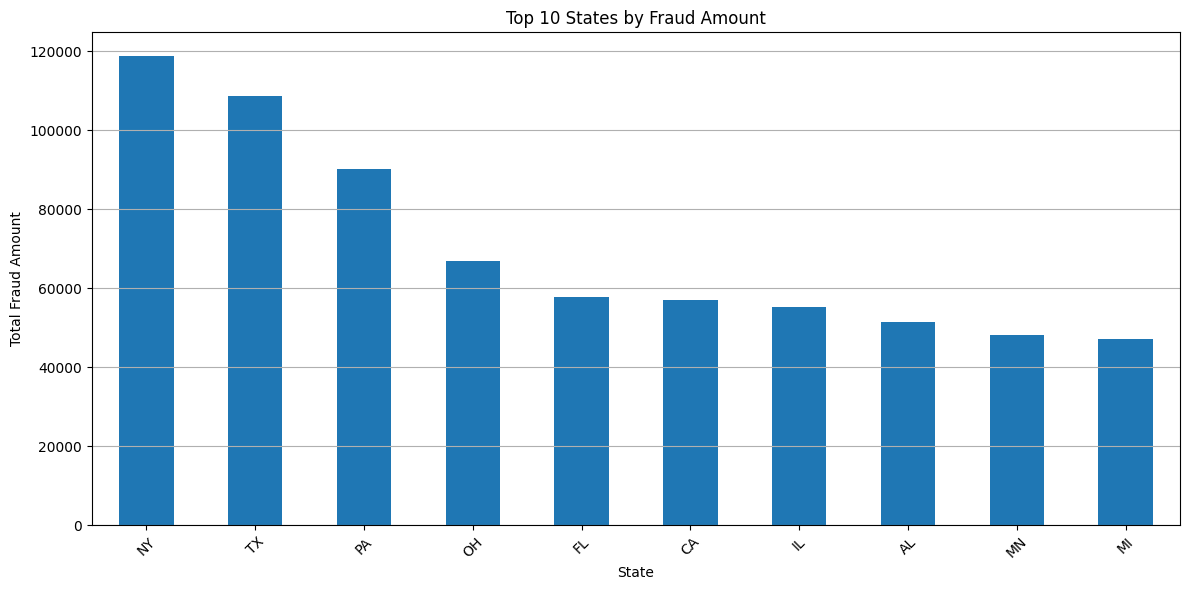

In [214]:
plt.figure(figsize=(12, 6))

fraud_amount_state.head(10).plot(kind='bar')

plt.title('Top 10 States by Fraud Amount')
plt.xlabel('State')
plt.ylabel('Total Fraud Amount')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()
plt.show()

In [215]:
fraud_by_hour = df[df['is_fraud'] == 1].groupby('transaction_hour').size()

fraud_by_hour = fraud_by_hour.sort_values(ascending=False)

print(fraud_by_hour)


transaction_hour
22    761
23    748
1     248
2     241
0     237
3     235
16     35
15     34
21     33
13     29
19     29
17     27
18     27
20     25
5      25
14     24
7      21
12     21
10     20
4      19
6      17
9      15
11     13
8      10
dtype: int64


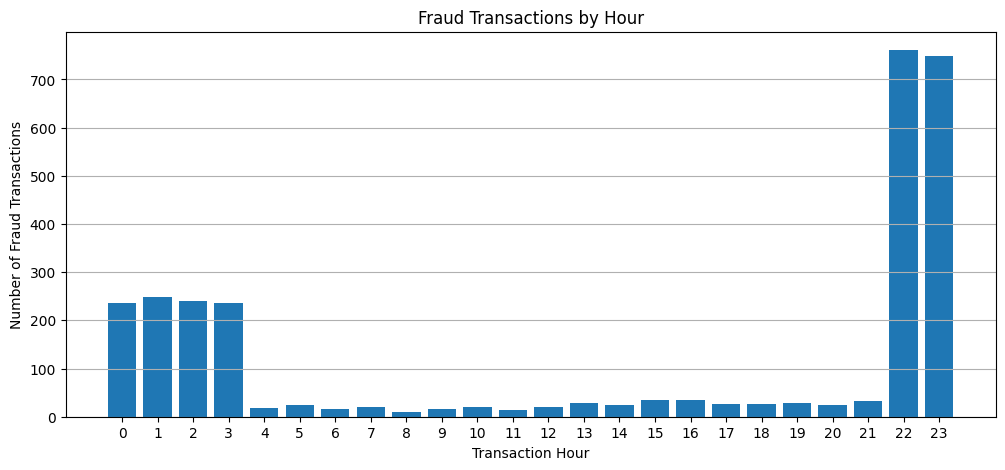

In [216]:
plt.figure(figsize=(12,5))

fraud_by_hour = fraud_by_hour.sort_index()

plt.bar(fraud_by_hour.index, fraud_by_hour.values)

plt.title("Fraud Transactions by Hour")
plt.xlabel("Transaction Hour")
plt.ylabel("Number of Fraud Transactions")

plt.xticks(range(24))
plt.grid(axis='y')

plt.show()

In [217]:
df['transaction_datetime'] = pd.to_datetime(df['transaction_datetime'])

df['day_of_week'] = df['transaction_datetime'].dt.day_name()

fraud_by_day = df[df['is_fraud'] == 1].groupby('day_of_week').size()

print(fraud_by_day)

day_of_week
Friday       391
Monday       449
Saturday     472
Sunday       478
Thursday     395
Tuesday      364
Wednesday    345
dtype: int64


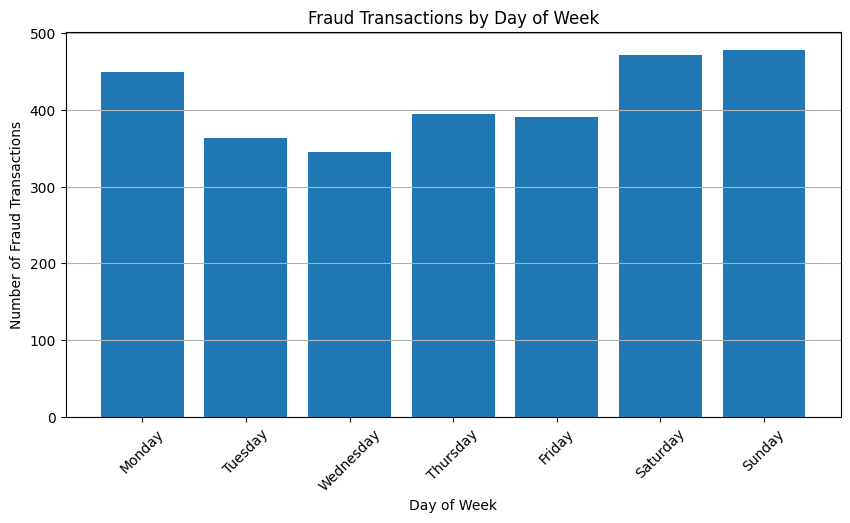

In [218]:
plt.figure(figsize=(10,5))

days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
              'Friday', 'Saturday', 'Sunday']

fraud_by_day = fraud_by_day.reindex(days_order)

plt.bar(fraud_by_day.index, fraud_by_day.values)

plt.title("Fraud Transactions by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Fraud Transactions")

plt.xticks(rotation=45)
plt.grid(axis='y')

plt.show()

In [219]:
fraud_amount_comparison = df.groupby('is_fraud')['transaction_amount'].mean()

print(fraud_amount_comparison)

is_fraud
0     68.021774
1    546.617868
Name: transaction_amount, dtype: float64


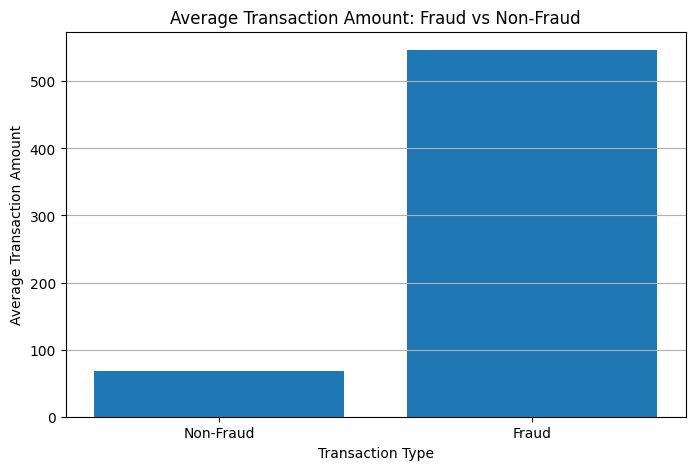

In [220]:
plt.figure(figsize=(8,5))

plt.bar(
    ['Non-Fraud', 'Fraud'],
    fraud_amount_comparison.values
)

plt.title("Average Transaction Amount: Fraud vs Non-Fraud")
plt.xlabel("Transaction Type")
plt.ylabel("Average Transaction Amount")

plt.grid(axis='y')
plt.show()

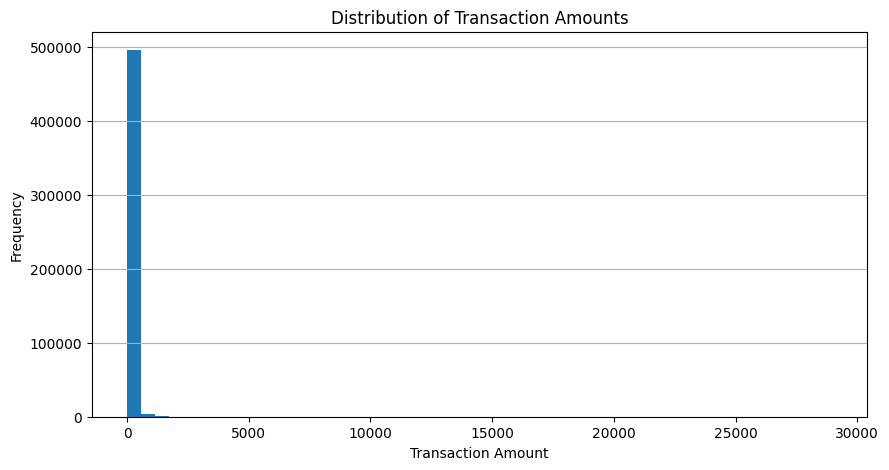

In [221]:
plt.figure(figsize=(10,5))

plt.hist(df['transaction_amount'], bins=50)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.grid(axis='y')
plt.show()

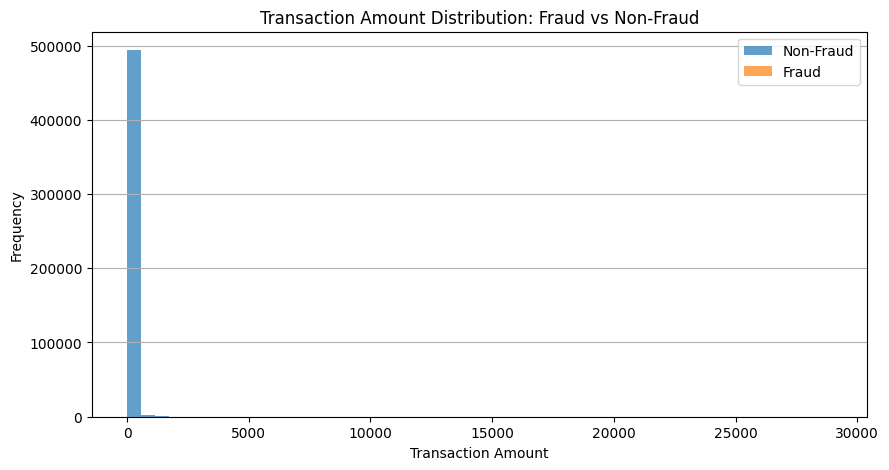

In [222]:
plt.figure(figsize=(10,5))

plt.hist(df[df['is_fraud'] == 0]['transaction_amount'],
         bins=50, alpha=0.7, label='Non-Fraud')

plt.hist(df[df['is_fraud'] == 1]['transaction_amount'],
         bins=50, alpha=0.7, label='Fraud')

plt.title("Transaction Amount Distribution: Fraud vs Non-Fraud")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.legend()
plt.grid(axis='y')

plt.show()

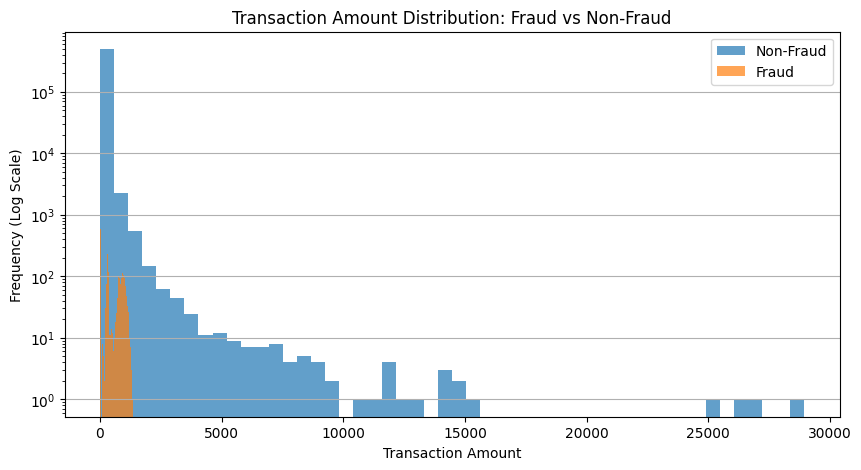

In [223]:
plt.figure(figsize=(10,5))

plt.hist(df[df['is_fraud'] == 0]['transaction_amount'],
         bins=50, alpha=0.7, label='Non-Fraud')

plt.hist(df[df['is_fraud'] == 1]['transaction_amount'],
         bins=50, alpha=0.7, label='Fraud')

plt.yscale('log')

plt.title("Transaction Amount Distribution: Fraud vs Non-Fraud")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency (Log Scale)")

plt.legend()
plt.grid(axis='y')

plt.show()

In [224]:
fraud_by_category = df[df['is_fraud'] == 1].groupby('merchant_category').size()

fraud_by_category = fraud_by_category.sort_values(ascending=False)

print(fraud_by_category)

merchant_category
shopping_net      693
grocery_pos       641
misc_net          372
shopping_pos      326
gas_transport     247
home               90
misc_pos           89
entertainment      89
kids_pets          85
personal_care      84
food_dining        49
health_fitness     44
travel             43
grocery_net        42
dtype: int64


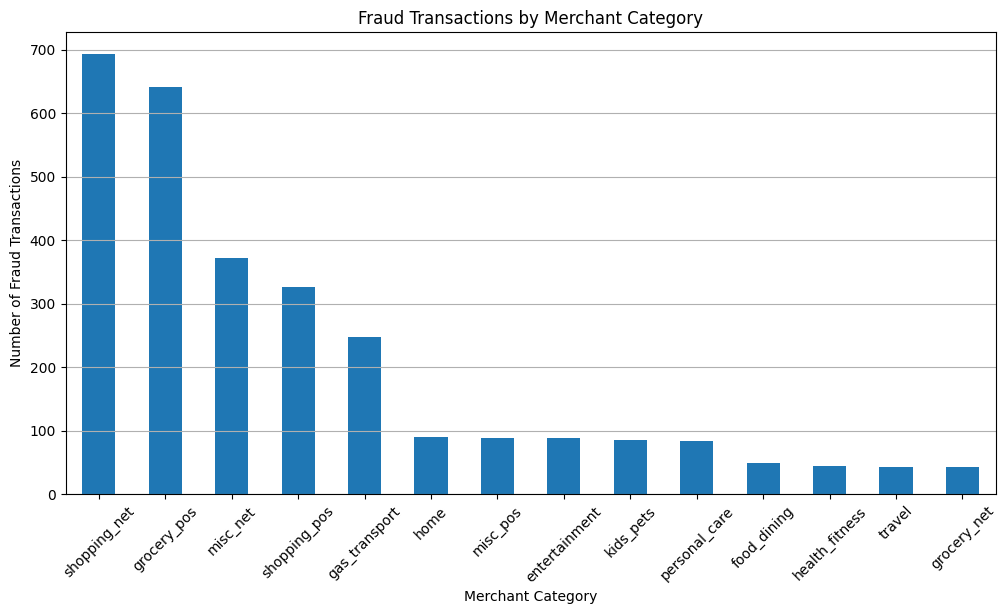

In [225]:
plt.figure(figsize=(12,6))

fraud_by_category.plot(kind='bar')

plt.title('Fraud Transactions by Merchant Category')
plt.xlabel('Merchant Category')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.show()

In [226]:
fraud_rate_category = df.groupby('merchant_category')['is_fraud'].mean() * 100

fraud_rate_category = fraud_rate_category.sort_values(ascending=False)

print(fraud_rate_category)

merchant_category
shopping_net      1.846080
misc_net          1.521659
grocery_pos       1.344323
shopping_pos      0.723640
gas_transport     0.486364
misc_pos          0.290110
travel            0.275218
entertainment     0.244143
personal_care     0.240405
grocery_net       0.238001
kids_pets         0.194767
home              0.190351
food_dining       0.139530
health_fitness    0.132882
Name: is_fraud, dtype: float64


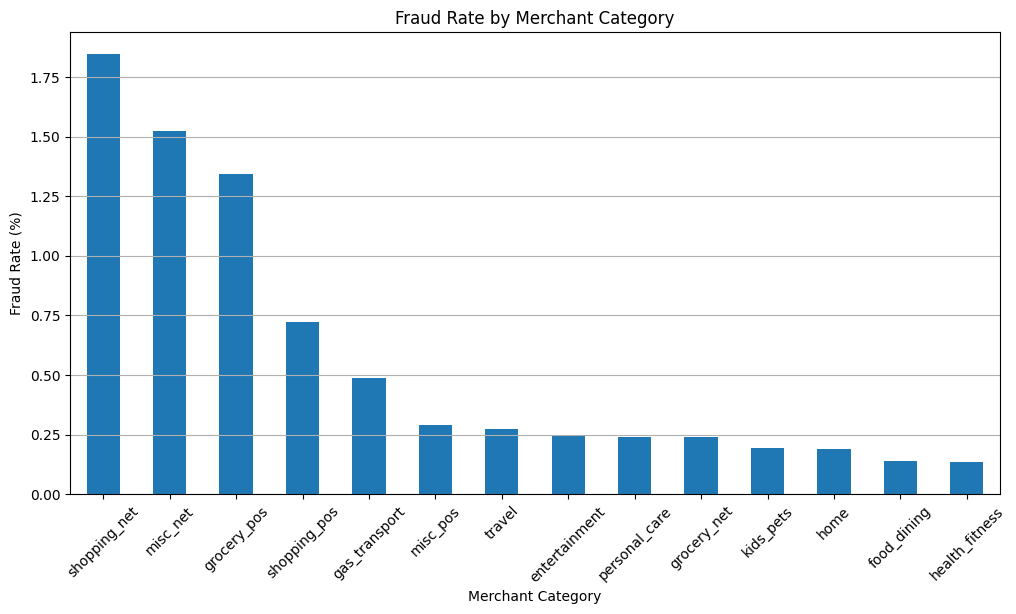

In [227]:
plt.figure(figsize=(12,6))

fraud_rate_category.plot(kind='bar')

plt.title('Fraud Rate by Merchant Category')
plt.xlabel('Merchant Category')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.show()

In [228]:
fraud_by_customer = df[df['is_fraud'] == 1].groupby('customer_id').size()

fraud_by_customer = fraud_by_customer.sort_values(ascending=False)

print(fraud_by_customer.head(10))

customer_id
CUST_0340538D8B29    10
CUST_4687CEAD8DED    10
CUST_6ECAE9DE0A50     9
CUST_9A34AEC9DABE     9
CUST_5379911D4E34     9
CUST_5B32948AEC52     9
CUST_C275D8E610DB     9
CUST_BFC5C9F1DC5E     9
CUST_764DBCD4FC8F     9
CUST_14A503C2C0A0     9
dtype: int64


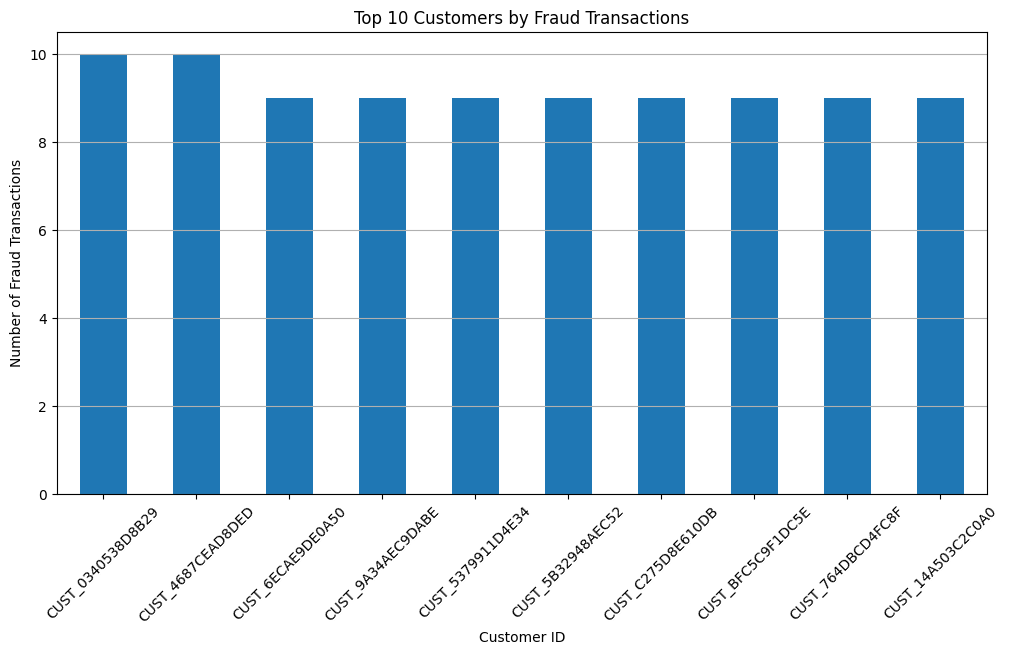

In [229]:
plt.figure(figsize=(12,6))

fraud_by_customer.head(10).plot(kind='bar')

plt.title('Top 10 Customers by Fraud Transactions')
plt.xlabel('Customer ID')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=45)

plt.grid(axis='y')

plt.show()

In [230]:
fraud_amount_customer = df[df['is_fraud'] == 1].groupby('customer_id')['transaction_amount'].sum()

fraud_amount_customer = fraud_amount_customer.sort_values(ascending=False)

print(fraud_amount_customer.head(10))

customer_id
CUST_C275D8E610DB    6211.42
CUST_F9D884D74B97    6143.50
CUST_E3C75A872838    6027.59
CUST_D78A9869D2AB    5970.65
CUST_E09C833528C9    5717.55
CUST_4BB515C9D14A    5526.53
CUST_A5154695C553    5489.31
CUST_5379911D4E34    5450.83
CUST_467F5606CAAD    5369.47
CUST_C881EA443AEE    5358.05
Name: transaction_amount, dtype: float64


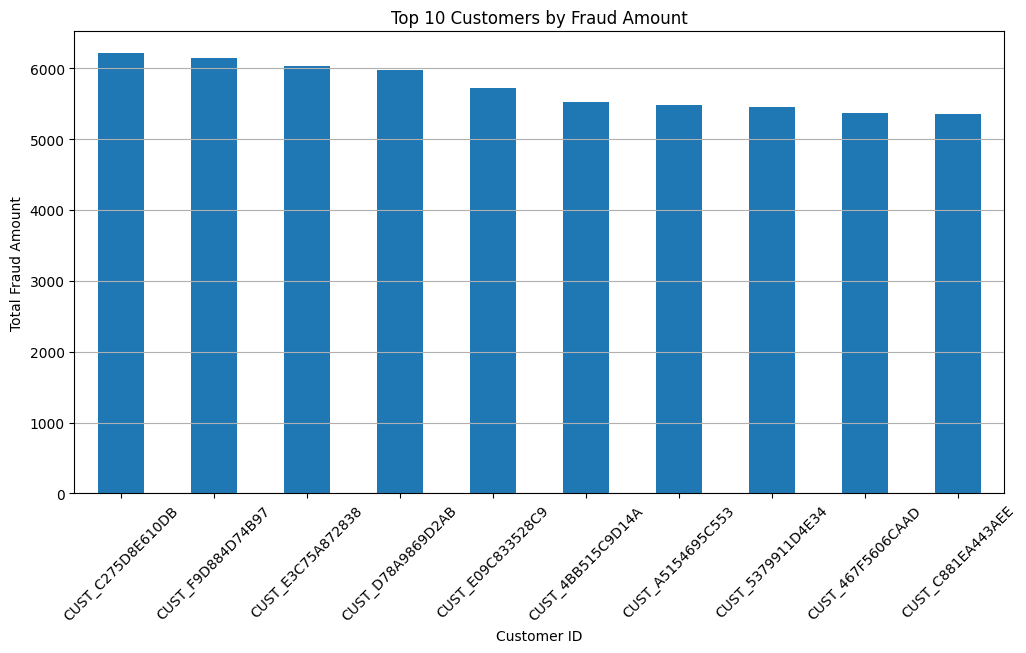

In [231]:
plt.figure(figsize=(12,6))

fraud_amount_customer.head(10).plot(kind='bar')

plt.title('Top 10 Customers by Fraud Amount')
plt.xlabel('Customer ID')
plt.ylabel('Total Fraud Amount')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.show()

In [232]:
fraud_by_gender = df[df['is_fraud'] == 1].groupby('gender').size()

print(fraud_by_gender)

fraud_by_gender.plot(kind='bar', figsize=(8,5))

plt.title('Fraud Transactions by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=0)
plt.grid(axis='y')

plt.show()

KeyError: 'gender'

In [233]:
print(df.columns)

Index(['transaction_id', 'customer_id', 'transaction_datetime',
       'transaction_date', 'transaction_hour', 'merchant', 'merchant_category',
       'transaction_amount', 'payment_method', 'transaction_status', 'city',
       'state', 'customer_latitude', 'customer_longitude', 'merchant_latitude',
       'merchant_longitude', 'city_population', 'is_fraud', 'day_of_week'],
      dtype='object')


payment_method
Chip           998
Contactless    450
Online         704
Swipe          742
dtype: int64


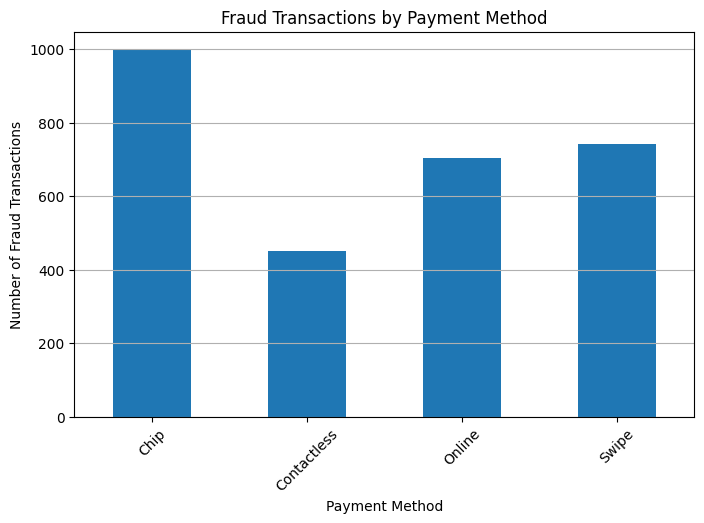

In [234]:
fraud_by_payment = df[df['is_fraud'] == 1].groupby('payment_method').size()

print(fraud_by_payment)

fraud_by_payment.plot(kind='bar', figsize=(8,5))

plt.title('Fraud Transactions by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.show()

payment_method
Chip           545231.54
Swipe          403843.74
Online         373495.20
Contactless    259341.63
Name: transaction_amount, dtype: float64


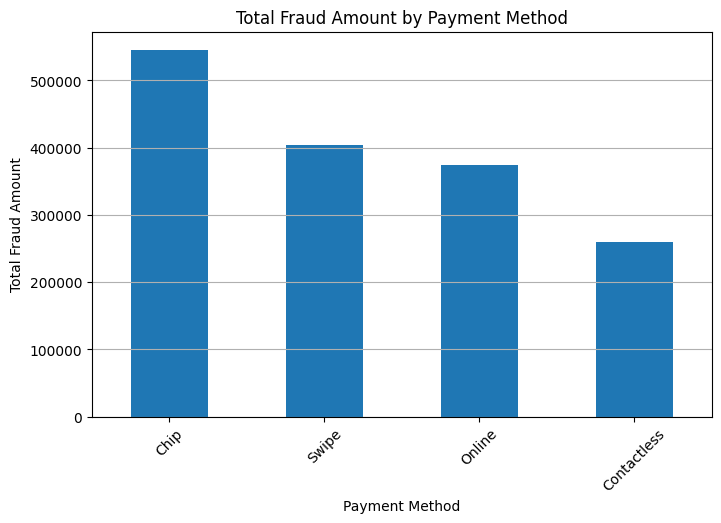

In [235]:
fraud_amount_payment = df[df['is_fraud'] == 1].groupby('payment_method')['transaction_amount'].sum()

fraud_amount_payment = fraud_amount_payment.sort_values(ascending=False)

print(fraud_amount_payment)

fraud_amount_payment.plot(kind='bar', figsize=(8,5))

plt.title('Total Fraud Amount by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Total Fraud Amount')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.show()

payment_method
Contactless    0.603865
Chip           0.586383
Swipe          0.569359
Online         0.563371
Name: is_fraud, dtype: float64


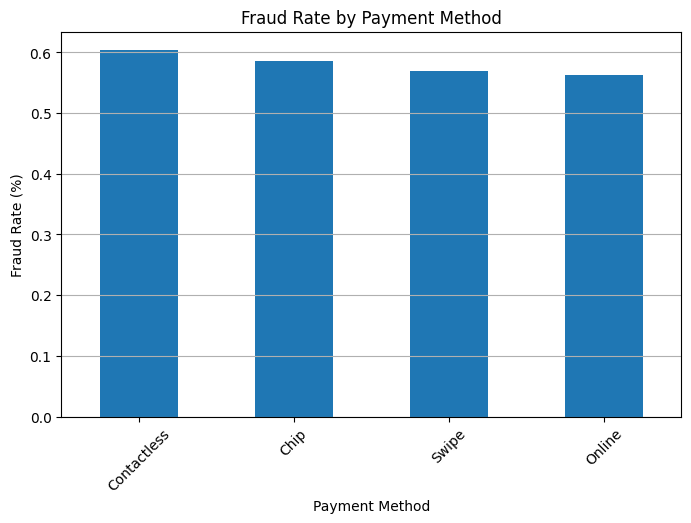

In [236]:
fraud_rate_payment = df.groupby('payment_method')['is_fraud'].mean() * 100

fraud_rate_payment = fraud_rate_payment.sort_values(ascending=False)

print(fraud_rate_payment)

fraud_rate_payment.plot(kind='bar', figsize=(8,5))

plt.title('Fraud Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.show()

transaction_status
Approved    2780
Declined      66
Pending       11
Reversed      37
dtype: int64


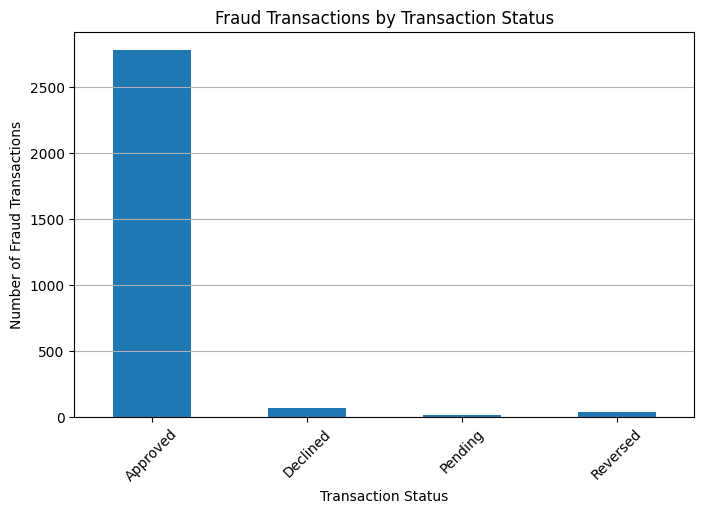

In [237]:
fraud_by_status = df[df['is_fraud'] == 1].groupby('transaction_status').size()

print(fraud_by_status)

fraud_by_status.plot(kind='bar', figsize=(8,5))

plt.title('Fraud Transactions by Transaction Status')
plt.xlabel('Transaction Status')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

city
Houston        18
Tulsa          14
San Antonio    13
Utica          12
Bay City       12
Warren         11
Naples         11
Detroit        11
Albuquerque    10
Lowell         10
dtype: int64


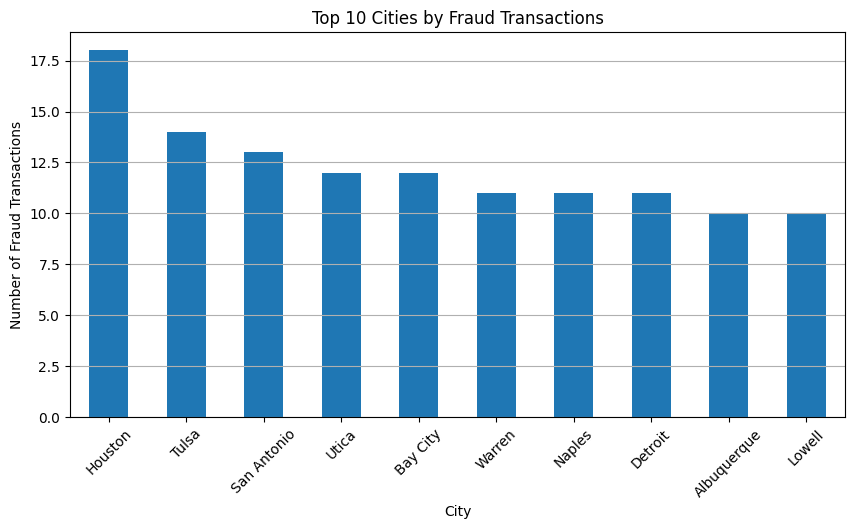

In [238]:
fraud_by_city = df[df['is_fraud'] == 1].groupby('city').size()

fraud_by_city = fraud_by_city.sort_values(ascending=False).head(10)

print(fraud_by_city)

fraud_by_city.plot(kind='bar', figsize=(10,5))

plt.title('Top 10 Cities by Fraud Transactions')
plt.xlabel('City')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

state
NY    208
TX    198
PA    165
OH    130
CA    116
IL    106
FL     98
MO     89
MN     87
MI     87
dtype: int64


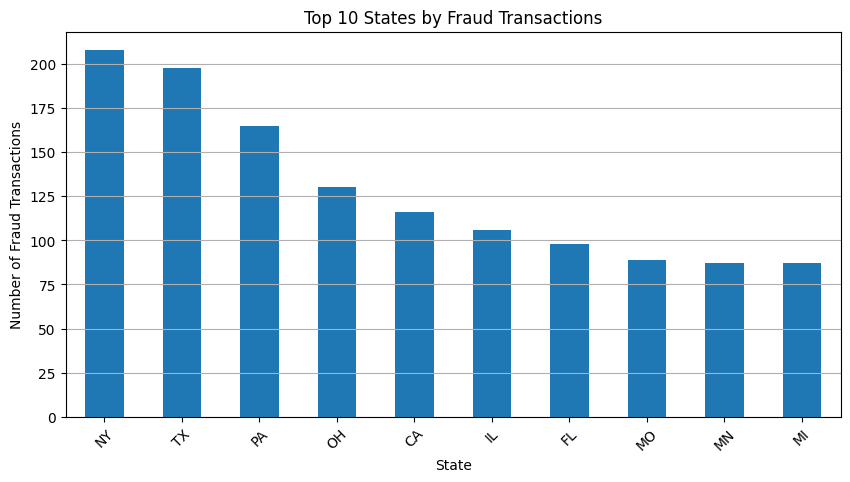

In [239]:
fraud_by_state = df[df['is_fraud'] == 1].groupby('state').size()

fraud_by_state = fraud_by_state.sort_values(ascending=False).head(10)

print(fraud_by_state)

fraud_by_state.plot(kind='bar', figsize=(10,5))

plt.title('Top 10 States by Fraud Transactions')
plt.xlabel('State')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

state
NY    118859.83
TX    108792.19
PA     90247.26
OH     66807.31
FL     57713.88
CA     57027.70
IL     55182.09
AL     51317.57
MN     48107.73
MI     47051.71
Name: transaction_amount, dtype: float64


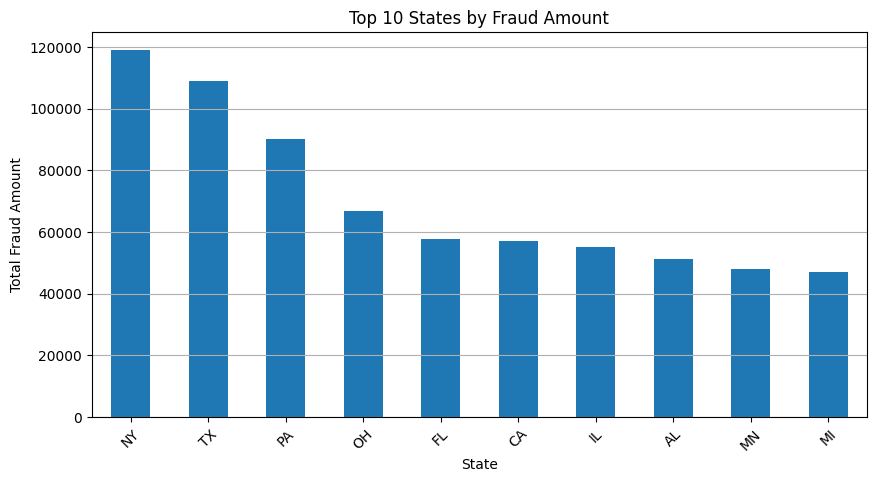

In [240]:
fraud_amount_by_state = df[df['is_fraud'] == 1].groupby('state')['transaction_amount'].sum()

fraud_amount_by_state = fraud_amount_by_state.sort_values(ascending=False).head(10)

print(fraud_amount_by_state)

fraud_amount_by_state.plot(kind='bar', figsize=(10,5))

plt.title('Top 10 States by Fraud Amount')
plt.xlabel('State')
plt.ylabel('Total Fraud Amount')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

city_population
23          2
37          2
46          6
47          1
49          5
           ..
1577385     8
1595797    13
2383912     4
2504700     3
2906700    18
Length: 685, dtype: int64


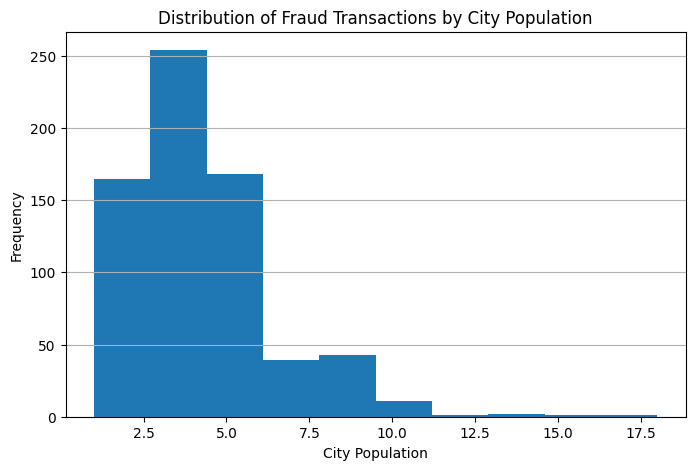

In [241]:
fraud_by_population = df[df['is_fraud'] == 1].groupby('city_population').size()

print(fraud_by_population)

fraud_by_population.plot(kind='hist', bins=10, figsize=(8,5))

plt.title('Distribution of Fraud Transactions by City Population')
plt.xlabel('City Population')
plt.ylabel('Frequency')
plt.grid(axis='y')
plt.show()

transaction_month
1     343
2     351
3     367
4     230
5     333
6     285
7     125
8     150
9     150
10    176
11    149
12    235
dtype: int64


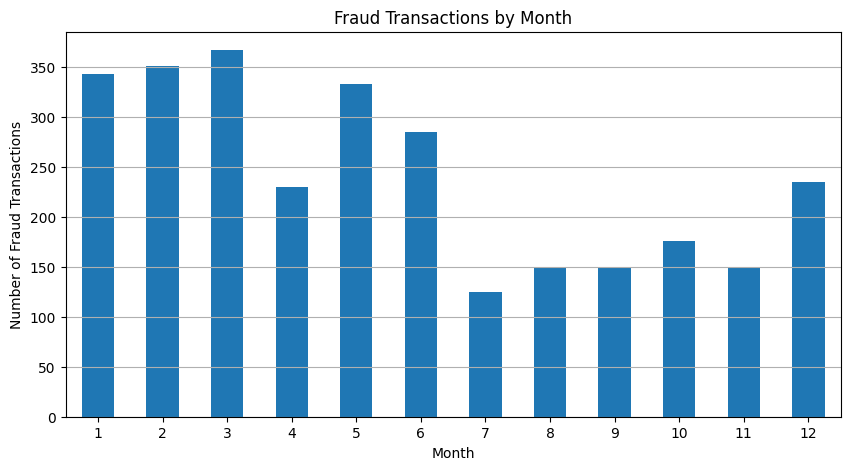

In [242]:
df['transaction_datetime'] = pd.to_datetime(df['transaction_datetime'])

df['transaction_month'] = df['transaction_datetime'].dt.month

fraud_by_month = df[df['is_fraud'] == 1].groupby('transaction_month').size()

print(fraud_by_month)

fraud_by_month.plot(kind='bar', figsize=(10,5))

plt.title('Fraud Transactions by Month')
plt.xlabel('Month')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

transaction_year
2019    2006
2020     888
dtype: int64


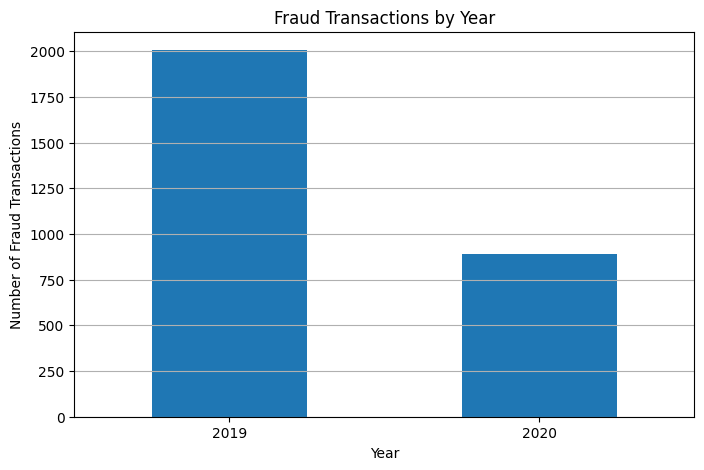

In [243]:
df['transaction_year'] = df['transaction_datetime'].dt.year

fraud_by_year = df[df['is_fraud'] == 1].groupby('transaction_year').size()

print(fraud_by_year)

fraud_by_year.plot(kind='bar', figsize=(8,5))

plt.title('Fraud Transactions by Year')
plt.xlabel('Year')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

transaction_month
1     197532.73
2     189818.47
3     179294.12
4     126093.35
5     189461.96
6     150460.09
7      77232.89
8      80469.82
9      70908.43
10    104865.50
11     83347.02
12    132427.73
Name: transaction_amount, dtype: float64


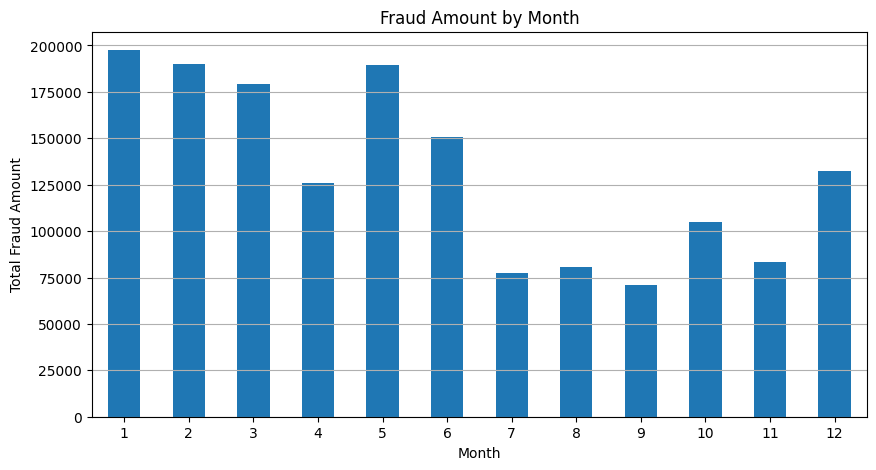

In [244]:
fraud_amount_by_month = df[df['is_fraud'] == 1].groupby('transaction_month')['transaction_amount'].sum()

print(fraud_amount_by_month)

fraud_amount_by_month.plot(kind='bar', figsize=(10,5))

plt.title('Fraud Amount by Month')
plt.xlabel('Month')
plt.ylabel('Total Fraud Amount')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

transaction_year
2019    1090116.09
2020     491796.02
Name: transaction_amount, dtype: float64


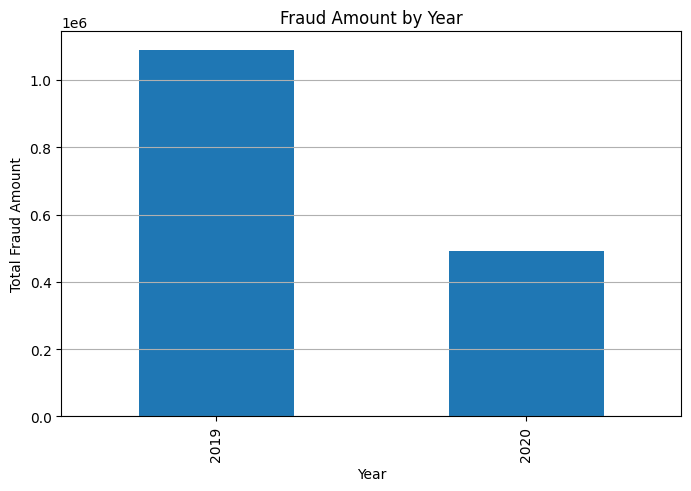

In [245]:
fraud_by_year = df[df['is_fraud'] == 1].groupby('transaction_year')['transaction_amount'].sum()

print(fraud_by_year)

fraud_by_year.plot(kind='bar', figsize=(8,5))

plt.title('Fraud Amount by Year')
plt.xlabel('Year')
plt.ylabel('Total Fraud Amount')
plt.grid(axis='y')
plt.show()

In [246]:
df['transaction_year'] = pd.to_datetime(df['transaction_date']).dt.year

day_of_week
Friday       216242.89
Monday       232556.83
Saturday     246775.18
Sunday       274786.02
Thursday     220252.75
Tuesday      200795.73
Wednesday    190502.71
Name: transaction_amount, dtype: float64


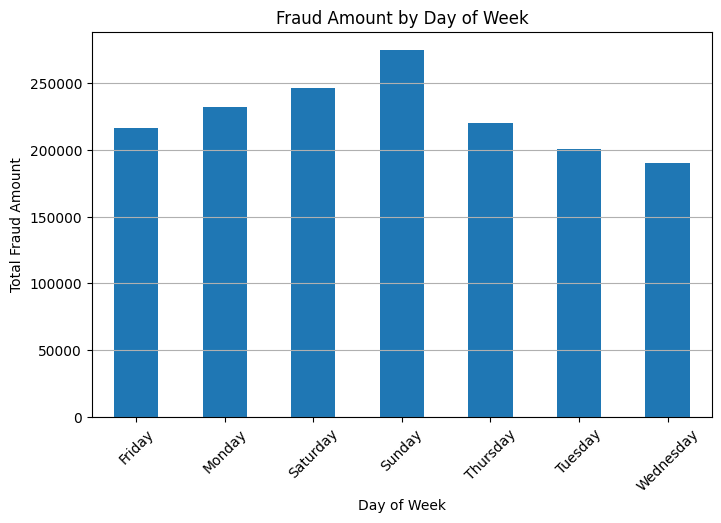

In [247]:
fraud_by_day = df[df['is_fraud'] == 1].groupby('day_of_week')['transaction_amount'].sum()

print(fraud_by_day)

fraud_by_day.plot(kind='bar', figsize=(8,5))

plt.title('Fraud Amount by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Total Fraud Amount')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

transaction_hour
0     237
1     248
2     241
3     235
4      19
5      25
6      17
7      21
8      10
9      15
10     20
11     13
12     21
13     29
14     24
15     34
16     35
17     27
18     27
19     29
20     25
21     33
22    761
23    748
dtype: int64


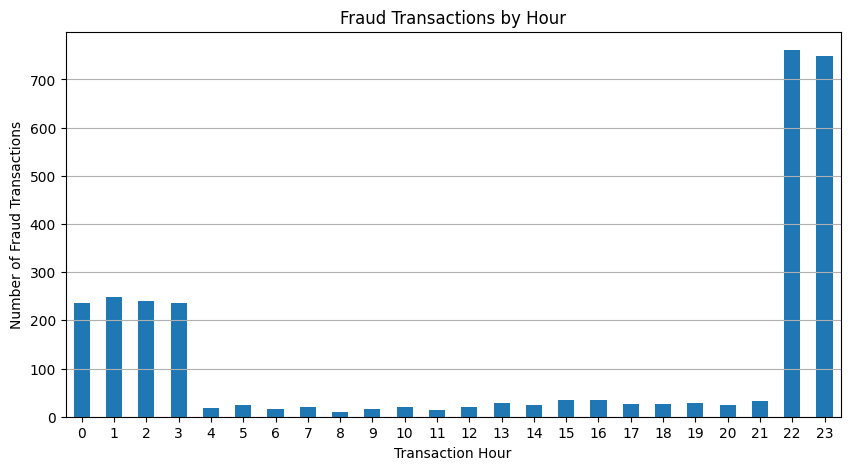

In [248]:
fraud_by_hour = df[df['is_fraud'] == 1].groupby('transaction_hour').size()

print(fraud_by_hour)

fraud_by_hour.plot(kind='bar', figsize=(10,5))

plt.title('Fraud Transactions by Hour')
plt.xlabel('Transaction Hour')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

In [249]:
print(data.columns)

NameError: name 'data' is not defined

In [250]:
import pandas as pd

df = pd.read_csv("credit_card_fraud_project_dataset_500k.csv")

In [251]:
print(df.shape)
print(df.columns)

(500000, 18)
Index(['transaction_id', 'customer_id', 'transaction_datetime',
       'transaction_date', 'transaction_hour', 'merchant', 'merchant_category',
       'transaction_amount', 'payment_method', 'transaction_status', 'city',
       'state', 'customer_latitude', 'customer_longitude', 'merchant_latitude',
       'merchant_longitude', 'city_population', 'is_fraud'],
      dtype='object')


transaction_hour
0     237
1     248
2     241
3     235
4      19
5      25
6      17
7      21
8      10
9      15
10     20
11     13
12     21
13     29
14     24
15     34
16     35
17     27
18     27
19     29
20     25
21     33
22    761
23    748
dtype: int64


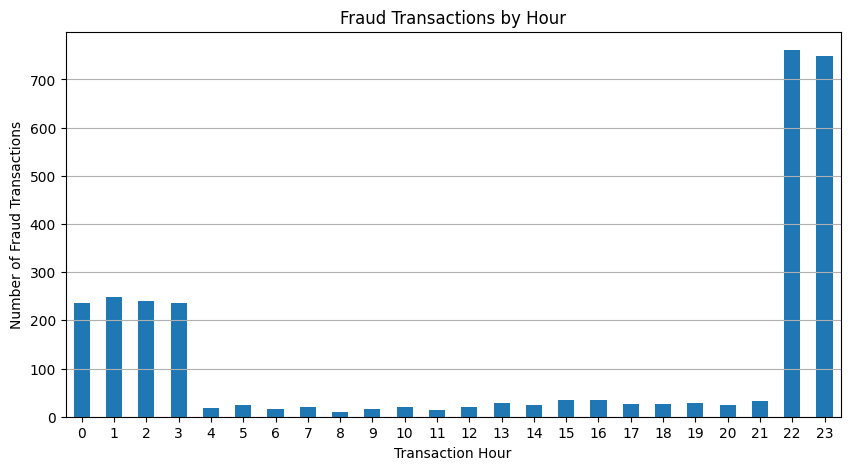

In [252]:
fraud_by_hour = df[df['is_fraud'] == 1].groupby('transaction_hour').size()

print(fraud_by_hour)

fraud_by_hour.plot(kind='bar', figsize=(10,5))

plt.title('Fraud Transactions by Hour')
plt.xlabel('Transaction Hour')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

transaction_hour
0      89983.08
1      87563.60
2      90534.86
3      81467.69
4       4521.83
5       8219.99
6       3919.73
7       6770.11
8       3667.45
9       2701.32
10      9097.45
11      4867.94
12     13035.40
13     18368.57
14     17613.41
15     22153.04
16     24105.57
17     17498.71
18     16950.07
19     19039.98
20     19073.19
21     23639.55
22    511509.28
23    485610.29
Name: transaction_amount, dtype: float64


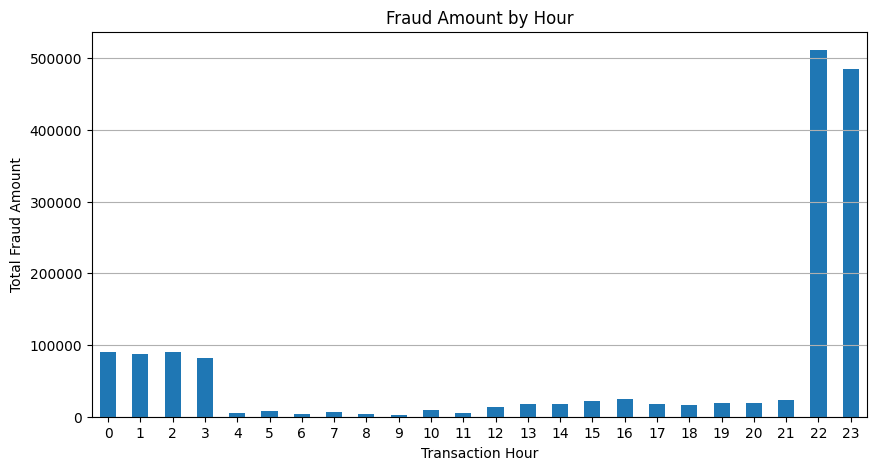

In [253]:
fraud_amount_by_hour = df[df['is_fraud'] == 1].groupby('transaction_hour')['transaction_amount'].sum()

print(fraud_amount_by_hour)

fraud_amount_by_hour.plot(kind='bar', figsize=(10,5))

plt.title('Fraud Amount by Hour')
plt.xlabel('Transaction Hour')
plt.ylabel('Total Fraud Amount')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()


merchant_category
shopping_net      693
grocery_pos       641
misc_net          372
shopping_pos      326
gas_transport     247
home               90
misc_pos           89
entertainment      89
kids_pets          85
personal_care      84
food_dining        49
health_fitness     44
travel             43
grocery_net        42
dtype: int64


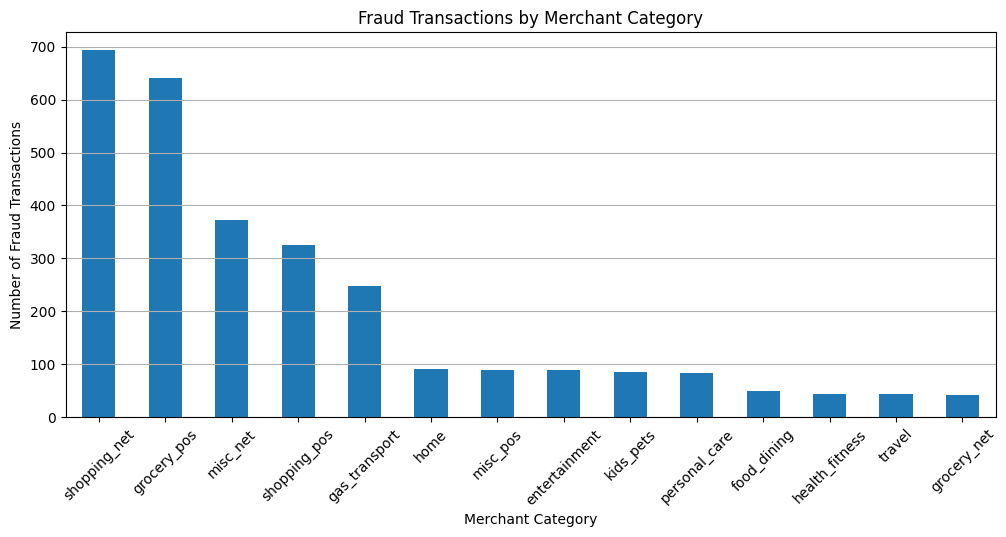

In [254]:
fraud_by_category = df[df['is_fraud'] == 1].groupby('merchant_category').size()

fraud_by_category = fraud_by_category.sort_values(ascending=False)

print(fraud_by_category)

fraud_by_category.plot(kind='bar', figsize=(12,5))

plt.title('Fraud Transactions by Merchant Category')
plt.xlabel('Merchant Category')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

merchant_category
shopping_net      693210.50
misc_net          295615.05
shopping_pos      287773.67
grocery_pos       200267.99
entertainment      45475.93
home               23331.11
misc_pos           21713.98
food_dining         5967.24
gas_transport       3052.93
personal_care       2212.41
kids_pets           1508.09
health_fitness       881.12
grocery_net          531.84
travel               370.25
Name: transaction_amount, dtype: float64


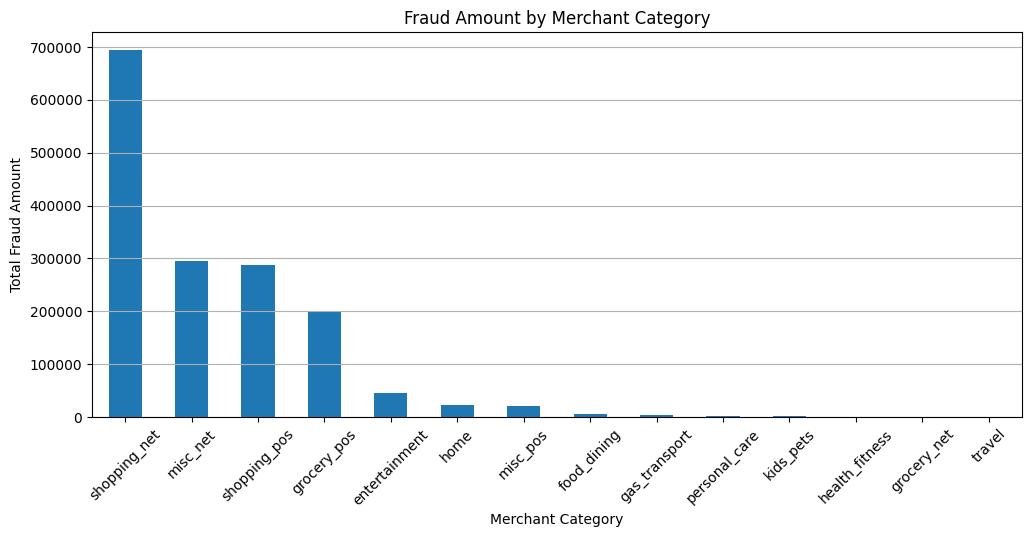

In [255]:
fraud_by_category_amount = df[df['is_fraud'] == 1].groupby('merchant_category')['transaction_amount'].sum().sort_values(ascending=False)

print(fraud_by_category_amount)

fraud_by_category_amount.plot(kind='bar', figsize=(12,5))

plt.title('Fraud Amount by Merchant Category')
plt.xlabel('Merchant Category')
plt.ylabel('Total Fraud Amount')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

In [256]:
fraud_by_day = df[df['is_fraud'] == 1].groupby('day_of_week').size()

print(fraud_by_day)

fraud_by_day.plot(kind='bar', figsize=(10,5))

plt.title('Fraud Transactions by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

KeyError: 'day_of_week'

In [257]:
df['transaction_date'] = pd.to_datetime(df['transaction_date'])

df['day_of_week'] = df['transaction_date'].dt.day_name()

In [258]:
fraud_by_day = df[df['is_fraud'] == 1].groupby('day_of_week').size()

print(fraud_by_day)

day_of_week
Friday       391
Monday       449
Saturday     472
Sunday       478
Thursday     395
Tuesday      364
Wednesday    345
dtype: int64


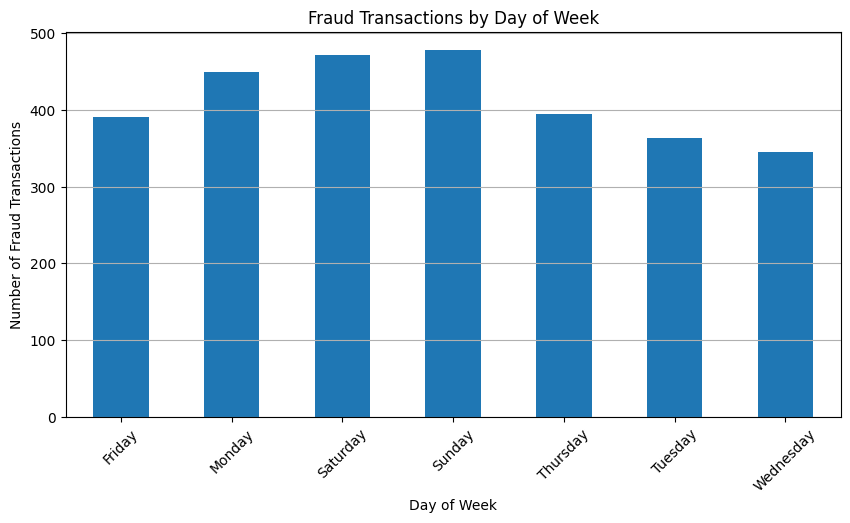

In [259]:
fraud_by_day.plot(kind='bar', figsize=(10,5))

plt.title('Fraud Transactions by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

day_of_week
Friday       216242.89
Monday       232556.83
Saturday     246775.18
Sunday       274786.02
Thursday     220252.75
Tuesday      200795.73
Wednesday    190502.71
Name: transaction_amount, dtype: float64


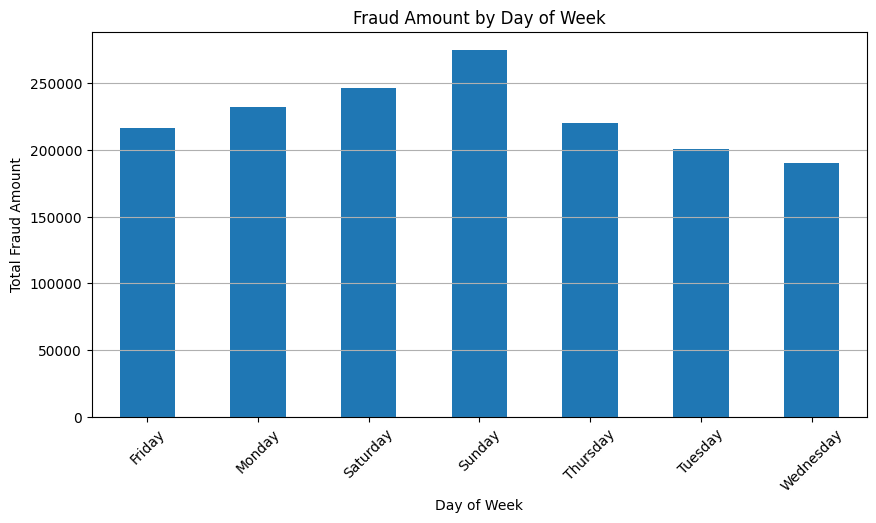

In [260]:
fraud_amount_by_day = df[df['is_fraud'] == 1].groupby('day_of_week')['transaction_amount'].sum()

print(fraud_amount_by_day)

fraud_amount_by_day.plot(kind='bar', figsize=(10,5))

plt.title('Fraud Amount by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Total Fraud Amount')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

In [261]:
fraud_rate_category = data.groupby('merchant_category')['is_fraud'].mean() * 100

print(fraud_rate_category.sort_values(ascending=False))

NameError: name 'data' is not defined

In [262]:
print(df.columns)

Index(['transaction_id', 'customer_id', 'transaction_datetime',
       'transaction_date', 'transaction_hour', 'merchant', 'merchant_category',
       'transaction_amount', 'payment_method', 'transaction_status', 'city',
       'state', 'customer_latitude', 'customer_longitude', 'merchant_latitude',
       'merchant_longitude', 'city_population', 'is_fraud', 'day_of_week'],
      dtype='object')


In [263]:
%whos

Variable                    Type         Data/Info
--------------------------------------------------
average_customer_spending   Series       customer_id\nCUST_00686B4<...>ngth: 982, dtype: float64
avg_amount_by_hour          Series       transaction_hour\n0     8<...>on_amount, dtype: float64
avg_spending_customer       Series       customer_id\nCUST_AE7EE5C<...>ngth: 982, dtype: float64
category_fraud_rate         Series       merchant_category\nshoppi<...> is_fraud, dtype: float64
city_transactions           Series       city\nBirmingham     2201<...>Length: 893, dtype: int64
col                         str          is_fraud
correlation                 DataFrame                        trans<...>     0.002325  1.000000  
customer_spending           Series       customer_id\nCUST_3F12896<...>ngth: 982, dtype: float64
days_order                  list         n=7
df                          DataFrame                             <...>500000 rows x 19 columns]
fraud_amount               

In [264]:
fraud_rate_hour = df.groupby('transaction_hour')['is_fraud'].mean() * 100

print(fraud_rate_hour.sort_values(ascending=False))

transaction_hour
22    2.932337
23    2.883133
1     1.497585
2     1.468885
0     1.446975
3     1.413364
5     0.153224
16    0.137898
15    0.133553
21    0.131208
7     0.128236
10    0.123009
4     0.117698
19    0.115773
13    0.115212
17    0.107390
18    0.105304
6     0.103906
20    0.100616
14    0.095904
9     0.092925
12    0.083987
11    0.080188
8     0.060775
Name: is_fraud, dtype: float64


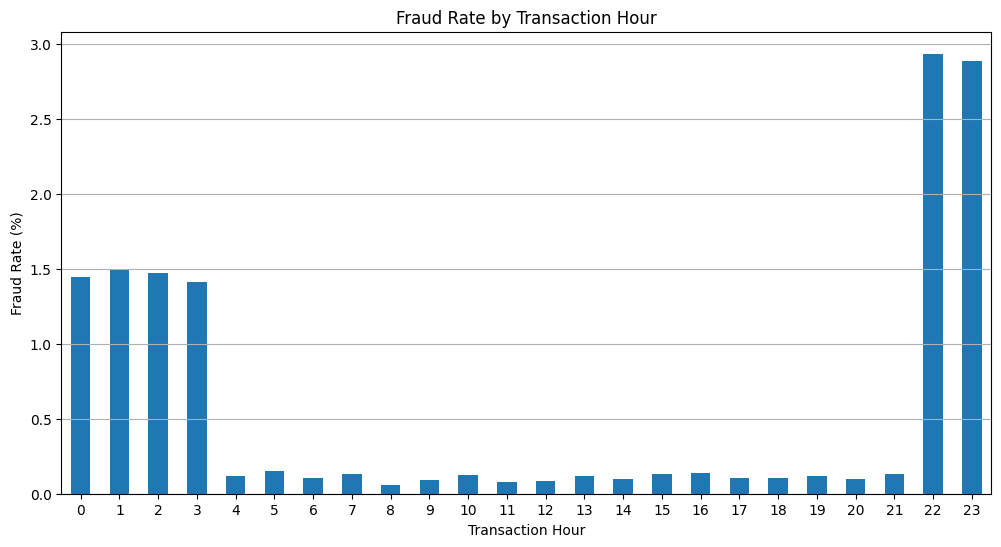

In [265]:
fraud_rate_hour = fraud_rate_hour.sort_index()

fraud_rate_hour.plot(kind='bar', figsize=(12,6))

plt.title('Fraud Rate by Transaction Hour')
plt.xlabel('Transaction Hour')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

In [266]:
fraud_rate_day = df.groupby('day_name')['is_fraud'].mean() * 100

print(fraud_rate_day.sort_values(ascending=False))

KeyError: 'day_name'

In [267]:
print(df.columns)

Index(['transaction_id', 'customer_id', 'transaction_datetime',
       'transaction_date', 'transaction_hour', 'merchant', 'merchant_category',
       'transaction_amount', 'payment_method', 'transaction_status', 'city',
       'state', 'customer_latitude', 'customer_longitude', 'merchant_latitude',
       'merchant_longitude', 'city_population', 'is_fraud', 'day_of_week'],
      dtype='object')


In [268]:
fraud_rate_day = df.groupby('day_of_week')['is_fraud'].mean() * 100

print(fraud_rate_day.sort_values(ascending=False))

day_of_week
Thursday     0.699239
Wednesday    0.681845
Friday       0.662678
Saturday     0.607840
Tuesday      0.587694
Sunday       0.494988
Monday       0.459326
Name: is_fraud, dtype: float64


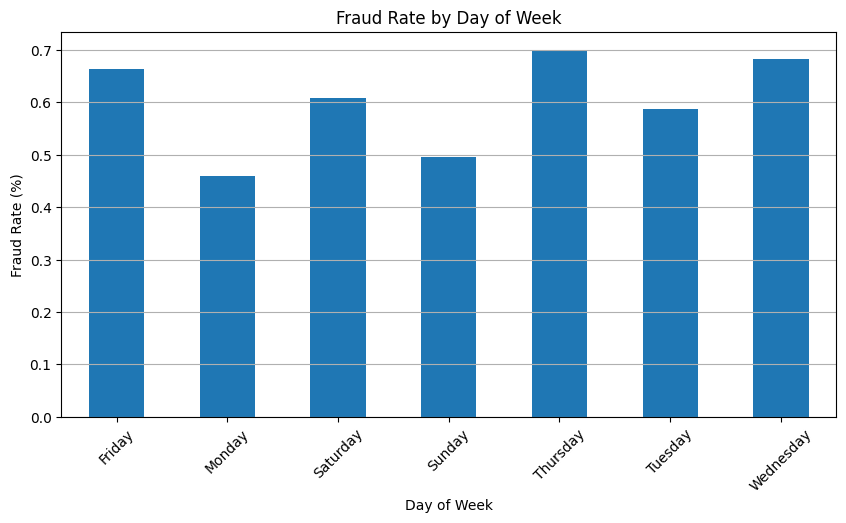

In [269]:
fraud_rate_day.plot(kind='bar', figsize=(10,5))

plt.title('Fraud Rate by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

In [270]:
fraud_rate_state = df.groupby('state')['is_fraud'].mean() * 100

print(fraud_rate_state.sort_values(ascending=False).head(10))

state
DE    100.000000
RI      3.755869
AK      2.319902
OR      0.881179
CO      0.788584
NH      0.763602
NE      0.741290
OH      0.723106
ME      0.715842
MN      0.711656
Name: is_fraud, dtype: float64


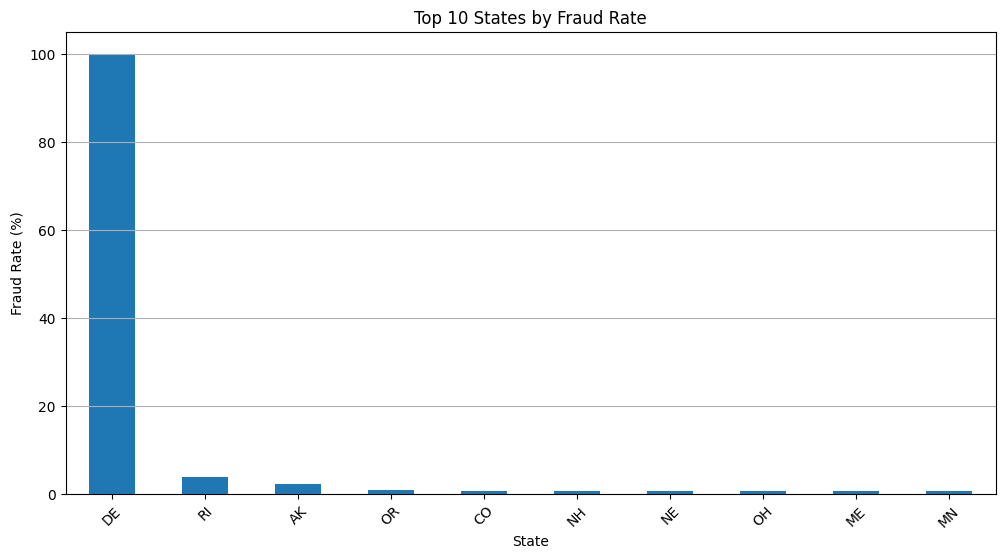

In [271]:
fraud_rate_state = fraud_rate_state.sort_values(ascending=False).head(10)

fraud_rate_state.plot(kind='bar', figsize=(12,6))

plt.title('Top 10 States by Fraud Rate')
plt.xlabel('State')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

In [272]:
state_transactions = df.groupby('state').size()

state_fraud = df[df['is_fraud'] == 1].groupby('state').size()

state_fraud_rate = (state_fraud / state_transactions) * 100

state_fraud_rate = state_fraud_rate[state_transactions >= 100]

print(state_fraud_rate.sort_values(ascending=False).head(10))

state
RI    3.755869
AK    2.319902
OR    0.881179
CO    0.788584
NH    0.763602
NE    0.741290
OH    0.723106
ME    0.715842
MN    0.711656
TN    0.691482
dtype: float64


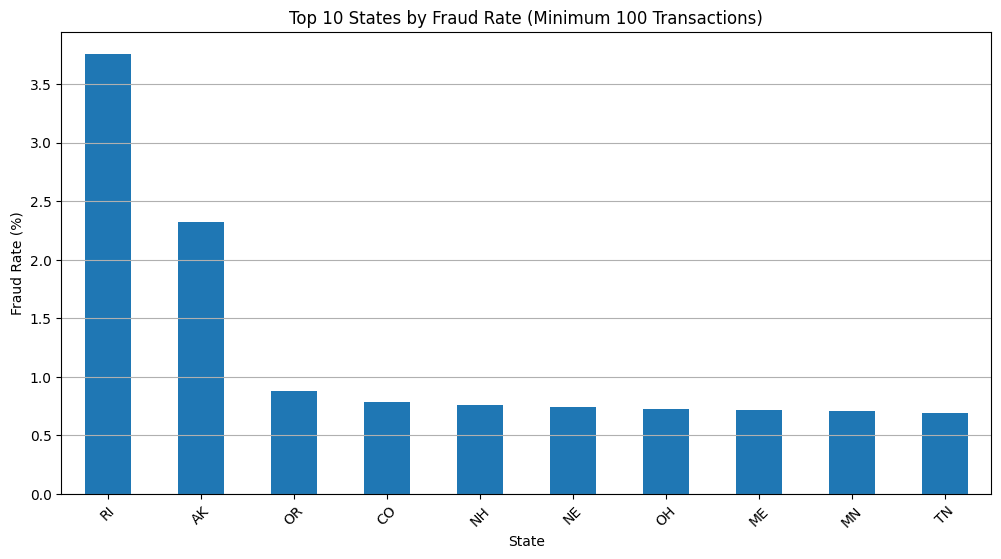

In [273]:
state_fraud_rate = state_fraud_rate.sort_values(ascending=False).head(10)

state_fraud_rate.plot(kind='bar', figsize=(12,6))

plt.title('Top 10 States by Fraud Rate (Minimum 100 Transactions)')
plt.xlabel('State')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

payment_method
Chip           998
Swipe          742
Online         704
Contactless    450
dtype: int64


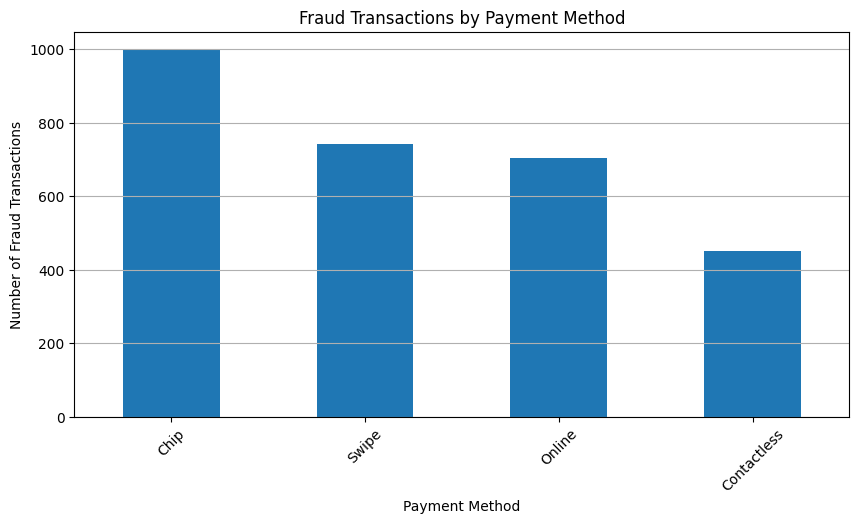

In [274]:
fraud_by_payment = df[df['is_fraud'] == 1].groupby('payment_method').size()

print(fraud_by_payment.sort_values(ascending=False))

fraud_by_payment.sort_values(ascending=False).plot(
    kind='bar',
    figsize=(10,5)
)

plt.title('Fraud Transactions by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

payment_method
Contactless    0.603865
Chip           0.586383
Swipe          0.569359
Online         0.563371
Name: is_fraud, dtype: float64


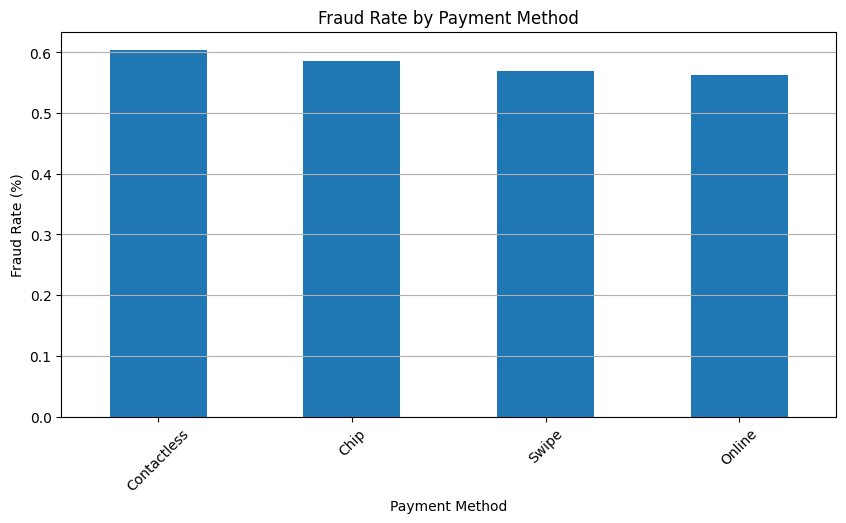

In [275]:
fraud_rate_payment = df.groupby('payment_method')['is_fraud'].mean() * 100

print(fraud_rate_payment.sort_values(ascending=False))

fraud_rate_payment.sort_values(ascending=False).plot(
    kind='bar',
    figsize=(10,5)
)

plt.title('Fraud Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

transaction_status
Approved    2780
Declined      66
Pending       11
Reversed      37
dtype: int64


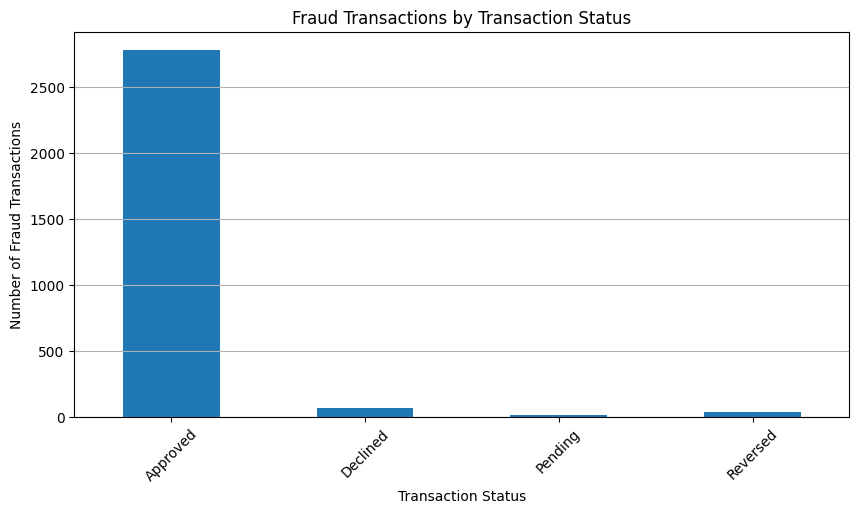

In [276]:
fraud_by_status = df[df['is_fraud'] == 1].groupby('transaction_status').size()

print(fraud_by_status)

fraud_by_status.plot(kind='bar', figsize=(10,5))

plt.title('Fraud Transactions by Transaction Status')
plt.xlabel('Transaction Status')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

transaction_status
Approved    1523086.70
Declined      30308.61
Reversed      21446.54
Pending        7070.26
Name: transaction_amount, dtype: float64


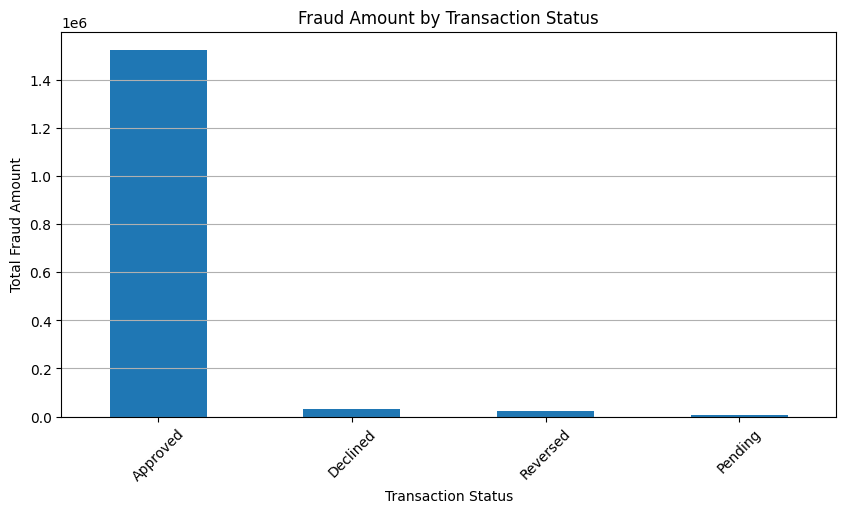

In [277]:
fraud_amount_status = df[df['is_fraud'] == 1].groupby('transaction_status')['transaction_amount'].sum()

print(fraud_amount_status.sort_values(ascending=False))

fraud_amount_status.sort_values(ascending=False).plot(
    kind='bar',
    figsize=(10,5)
)

plt.title('Fraud Amount by Transaction Status')
plt.xlabel('Transaction Status')
plt.ylabel('Total Fraud Amount')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

city
Houston        18
Tulsa          14
San Antonio    13
Utica          12
Bay City       12
Warren         11
Naples         11
Detroit        11
Albuquerque    10
Lowell         10
dtype: int64


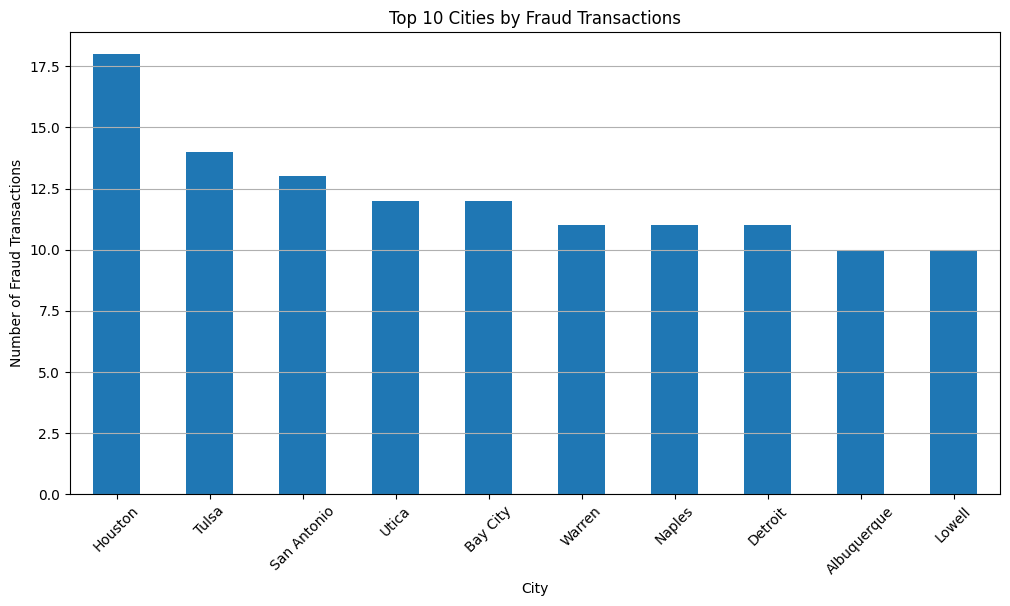

In [278]:
fraud_by_city = df[df['is_fraud'] == 1].groupby('city').size()

top_10_fraud_cities = fraud_by_city.sort_values(ascending=False).head(10)

print(top_10_fraud_cities)

top_10_fraud_cities.plot(kind='bar', figsize=(12,6))

plt.title('Top 10 Cities by Fraud Transactions')
plt.xlabel('City')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

is_fraud
0    497106
1      2894
Name: count, dtype: int64


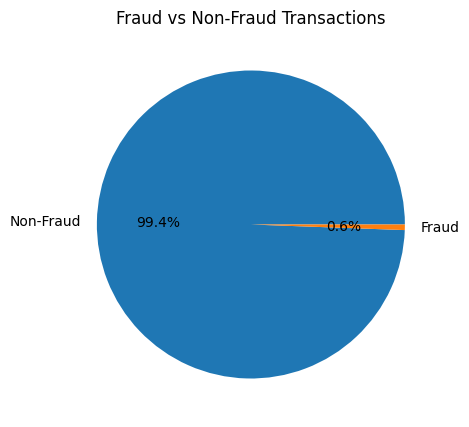

In [279]:
fraud_counts = df['is_fraud'].value_counts()

print(fraud_counts)

plt.figure(figsize=(7,5))
fraud_counts.plot(kind='pie', autopct='%1.1f%%', labels=['Non-Fraud', 'Fraud'])

plt.title('Fraud vs Non-Fraud Transactions')
plt.ylabel('')
plt.show()

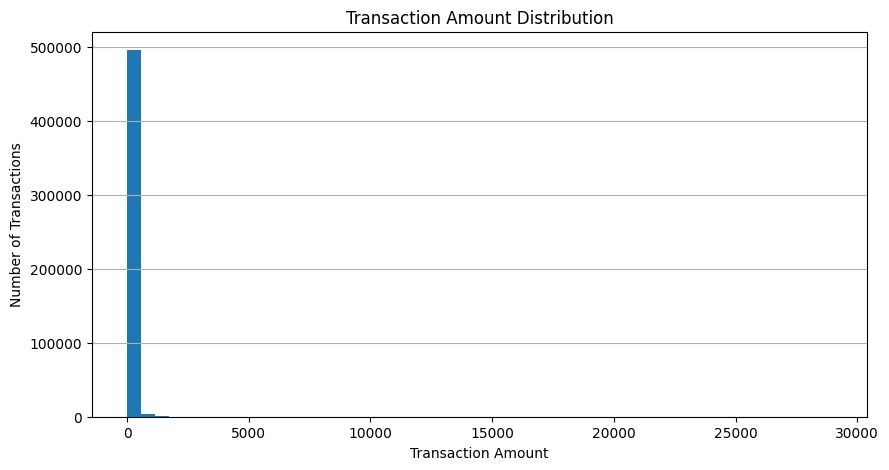

In [280]:
plt.figure(figsize=(10,5))

plt.hist(df['transaction_amount'], bins=50)

plt.title('Transaction Amount Distribution')
plt.xlabel('Transaction Amount')
plt.ylabel('Number of Transactions')

plt.grid(axis='y')
plt.show()

<Figure size 800x500 with 0 Axes>

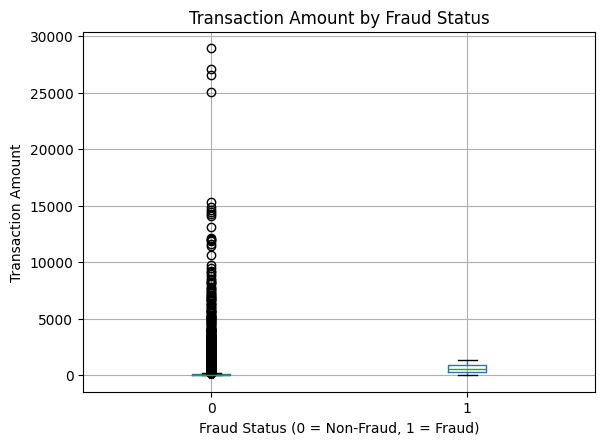

In [281]:
plt.figure(figsize=(8,5))

df.boxplot(column='transaction_amount', by='is_fraud')

plt.title('Transaction Amount by Fraud Status')
plt.suptitle('')
plt.xlabel('Fraud Status (0 = Non-Fraud, 1 = Fraud)')
plt.ylabel('Transaction Amount')

plt.show()

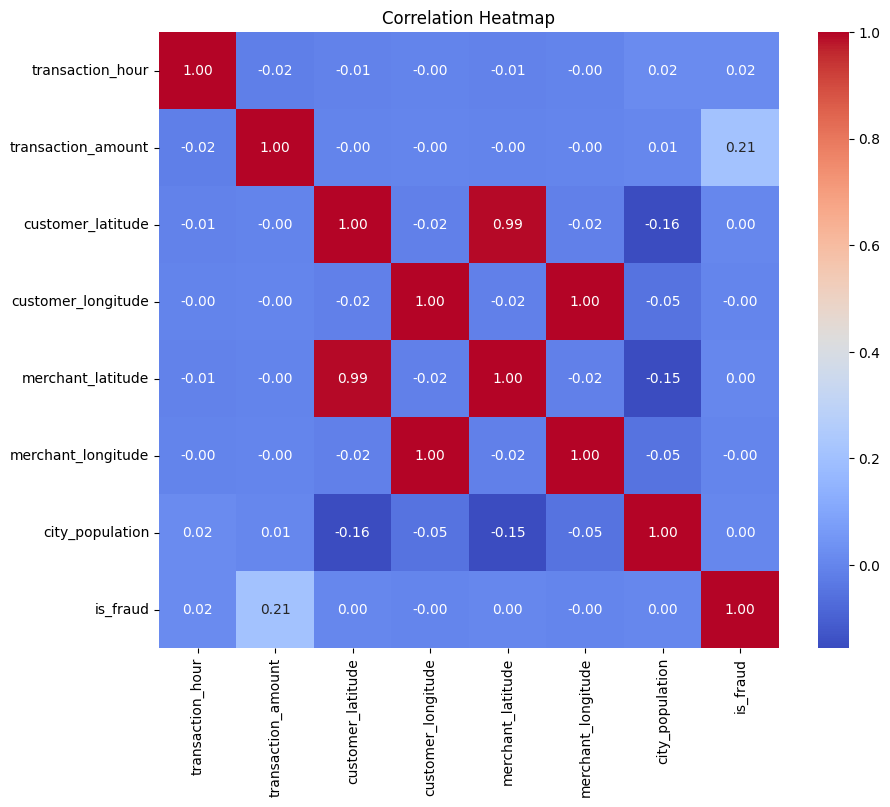

In [282]:
import seaborn as sns

plt.figure(figsize=(10,8))

correlation = df.select_dtypes(include='number').corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

amount_range
0-100          610
100-500        821
500-1000      1080
1000-5000      383
5000-10000       0
10000+           0
Name: count, dtype: int64


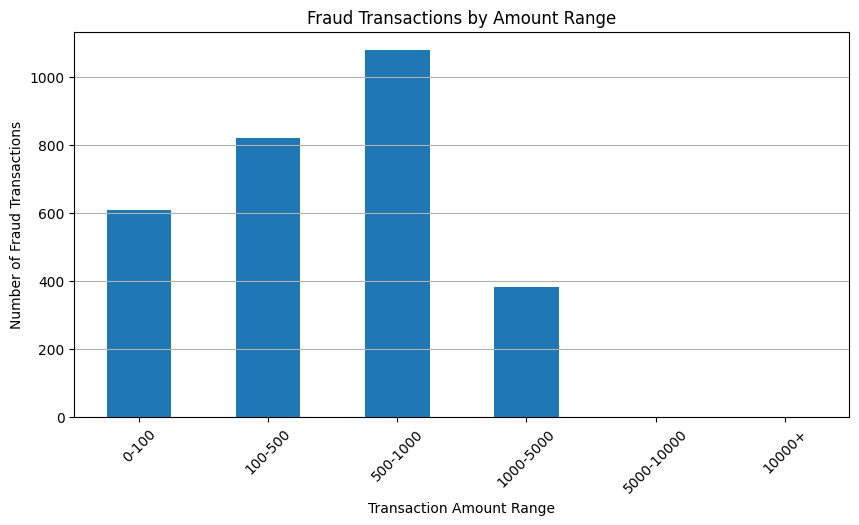

In [283]:
df['amount_range'] = pd.cut(
    df['transaction_amount'],
    bins=[0, 100, 500, 1000, 5000, 10000, 30000],
    labels=['0-100', '100-500', '500-1000', '1000-5000', '5000-10000', '10000+']
)

fraud_amount_range = df[df['is_fraud'] == 1]['amount_range'].value_counts().sort_index()

print(fraud_amount_range)

plt.figure(figsize=(10,5))

fraud_amount_range.plot(kind='bar')

plt.title('Fraud Transactions by Amount Range')
plt.xlabel('Transaction Amount Range')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=45)

plt.grid(axis='y')
plt.show()

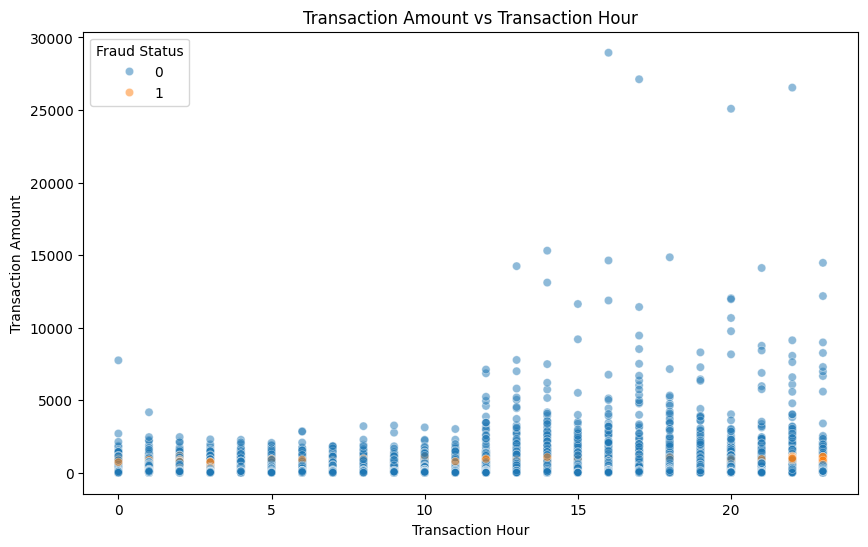

In [285]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='transaction_hour',
    y='transaction_amount',
    hue='is_fraud',
    alpha=0.5
)

plt.title('Transaction Amount vs Transaction Hour')
plt.xlabel('Transaction Hour')
plt.ylabel('Transaction Amount')
plt.legend(title='Fraud Status')
plt.show()


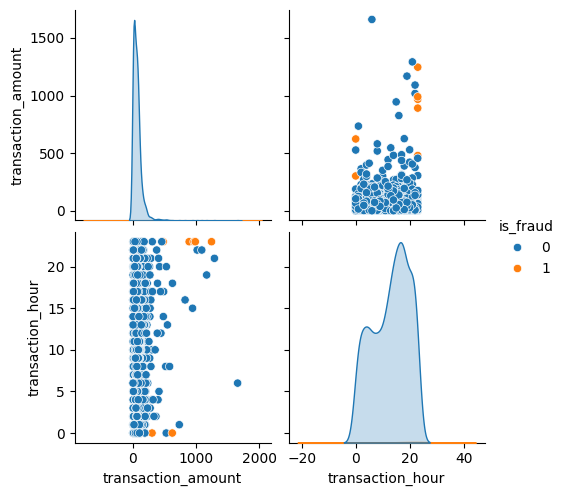

In [286]:
numeric_cols = ['transaction_amount', 'transaction_hour', 'is_fraud']

sns.pairplot(df.sample(2000, random_state=42)[numeric_cols], hue='is_fraud')

plt.show()

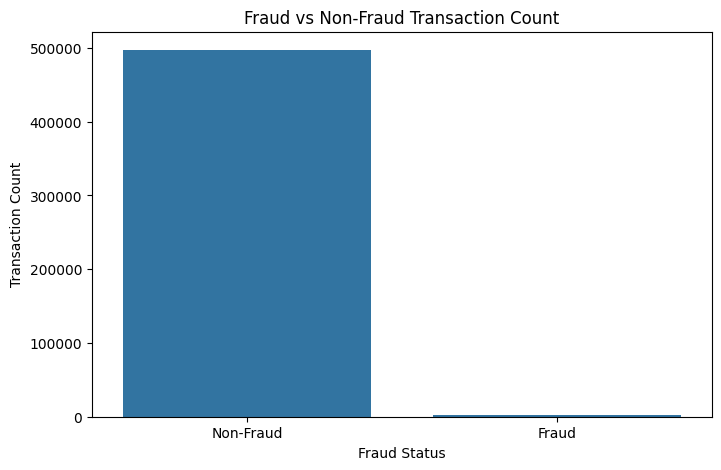

In [287]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='is_fraud')

plt.title('Fraud vs Non-Fraud Transaction Count')
plt.xlabel('Fraud Status')
plt.ylabel('Transaction Count')

plt.xticks([0, 1], ['Non-Fraud', 'Fraud'])

plt.show()

In [288]:
df['transaction_amount'].describe()

count    500000.000000
mean         70.791888
std         175.264083
min           1.000000
25%           9.660000
50%          47.560000
75%          83.190000
max       28948.900000
Name: transaction_amount, dtype: float64

In [289]:
df.groupby('is_fraud')['transaction_amount'].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,497106.0,68.021774,169.351107,1.00,9.6200,47.320,82.5700,28948.90
1,2894.0,546.617868,391.228497,1.06,260.4775,536.425,912.3425,1371.81


In [290]:
fraud_data = df[df['is_fraud'] == 1]

print("Total Fraud Transactions:", len(fraud_data))

print("Total Fraud Amount:", fraud_data['transaction_amount'].sum())

print("Average Fraud Transaction Amount:", fraud_data['transaction_amount'].mean())

print("Highest Fraud Transaction Amount:", fraud_data['transaction_amount'].max())

Total Fraud Transactions: 2894
Total Fraud Amount: 1581912.1099999999
Average Fraud Transaction Amount: 546.6178680027643
Highest Fraud Transaction Amount: 1371.81


In [291]:
fraud_by_category = df[df['is_fraud'] == 1].groupby('merchant_category').size().sort_values(ascending=False)

print(fraud_by_category)

merchant_category
shopping_net      693
grocery_pos       641
misc_net          372
shopping_pos      326
gas_transport     247
home               90
misc_pos           89
entertainment      89
kids_pets          85
personal_care      84
food_dining        49
health_fitness     44
travel             43
grocery_net        42
dtype: int64


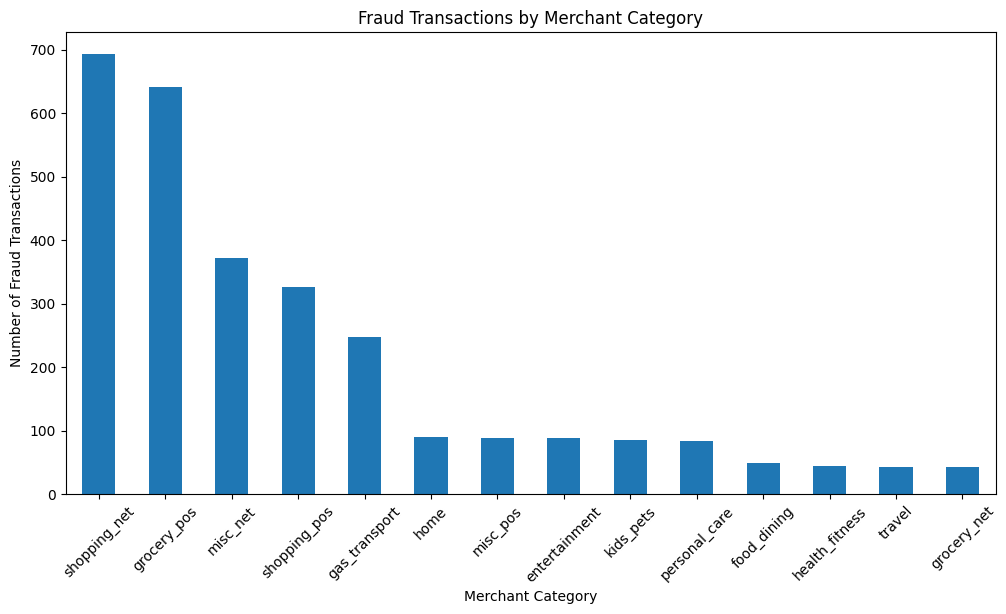

In [292]:
plt.figure(figsize=(12, 6))

fraud_by_category.plot(kind='bar')

plt.title('Fraud Transactions by Merchant Category')
plt.xlabel('Merchant Category')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=45)

plt.show()

In [293]:
fraud_by_hour = df[df['is_fraud'] == 1].groupby('transaction_hour').size().sort_values(ascending=False)

print(fraud_by_hour)

transaction_hour
22    761
23    748
1     248
2     241
0     237
3     235
16     35
15     34
21     33
13     29
19     29
17     27
18     27
20     25
5      25
14     24
7      21
12     21
10     20
4      19
6      17
9      15
11     13
8      10
dtype: int64


In [294]:
highest_fraud_hour = fraud_by_hour.idxmax()
highest_fraud_count = fraud_by_hour.max()

print("Highest Fraud Hour:", highest_fraud_hour)
print("Fraud Transactions:", highest_fraud_count)

Highest Fraud Hour: 22
Fraud Transactions: 761


In [295]:
total_transactions = len(df)

fraud_transactions = df[df['is_fraud'] == 1]

total_fraud = len(fraud_transactions)

fraud_percentage = (total_fraud / total_transactions) * 100

total_fraud_amount = fraud_transactions['transaction_amount'].sum()

avg_fraud_amount = fraud_transactions['transaction_amount'].mean()

print("===== BUSINESS INSIGHTS =====")
print("Total Transactions:", total_transactions)
print("Fraud Transactions:", total_fraud)
print("Fraud Percentage:", round(fraud_percentage, 2), "%")
print("Total Fraud Amount:", round(total_fraud_amount, 2))
print("Average Fraud Transaction:", round(avg_fraud_amount, 2))

===== BUSINESS INSIGHTS =====
Total Transactions: 500000
Fraud Transactions: 2894
Fraud Percentage: 0.58 %
Total Fraud Amount: 1581912.11
Average Fraud Transaction: 546.62


In [296]:
df.to_csv('credit_card_fraud_cleaned.csv', index=False)

In [297]:
import os

print(os.path.exists('credit_card_fraud_cleaned.csv'))

True


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\ramye\Downloads\DA Project\credit_card_fraud_cleaned.csv")

print(df.shape)

(500000, 20)


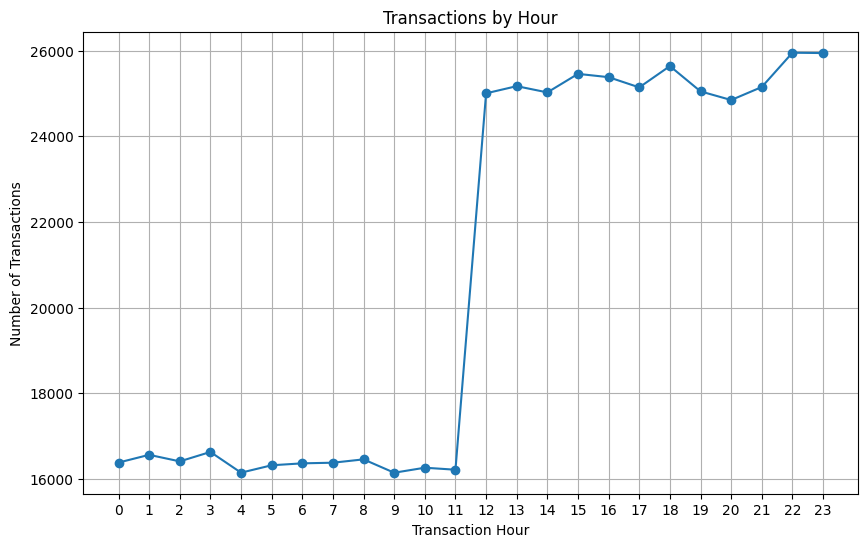

In [3]:
hourly_transactions = df.groupby('transaction_hour').size()

plt.figure(figsize=(10, 6))
plt.plot(hourly_transactions.index, hourly_transactions.values, marker='o')

plt.title('Transactions by Hour')
plt.xlabel('Transaction Hour')
plt.ylabel('Number of Transactions')
plt.xticks(range(24))
plt.grid(True)
plt.show()

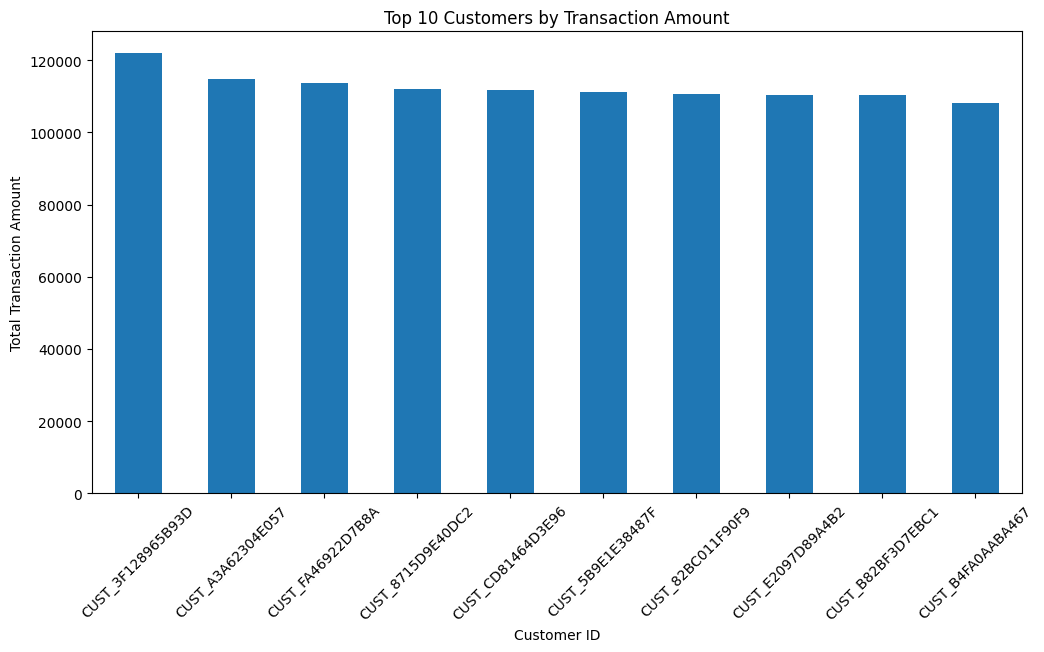

In [4]:
top_customers = df.groupby('customer_id')['transaction_amount'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
top_customers.plot(kind='bar')

plt.title('Top 10 Customers by Transaction Amount')
plt.xlabel('Customer ID')
plt.ylabel('Total Transaction Amount')
plt.xticks(rotation=45)
plt.show()